# 💊 Forecasting de unidades - OTC Health Solutions (OTCHS)

## Integrantes:

- Mateo Ramírez Cabrera
- Antonio Benítez Rueda

## Nota sobre los datos

Los datos de este parcial provienen de una empresa farmacéutica estadounidense. Los identificadores de productos y centros de distribución fueron anonimizados, y su uso en este curso es exclusivamente académico.

---

## Contexto e introducción

Una compañía farmacéutica estadounidense comercializa un portafolio de productos de venta libre agrupado en el segmento **OTCHS (Over The Counter Health Solutions)**: analgésicos, antigripales, digestivos, vitaminas y otros productos de cuidado personal que el consumidor compra sin fórmula médica 💊. Estos productos se despachan semanalmente desde varios **centros de distribución (CD)** hacia farmacias y cadenas minoristas en todo el país 🚚.

El área de *Demand Planning* construye hoy sus pronósticos con reglas simples (promedios de las últimas semanas) y sus resultados se revisan **trimestralmente** en el comité de S&OP (*Sales & Operations Planning*). En ese comité los errores de pronóstico se convierten en sobrecostos de inventario o en quiebres de stock, y el negocio necesita reducirlos 📉.

La demanda de estos productos trae varios retos: estacionalidad (p. ej., temporada de gripa y alergias), picos asociados a los ciclos de pedido de los clientes, productos que entran o salen del portafolio, semanas sin pedidos y diferencias de volumen grandes entre centros de distribución. Por eso es indispensable hacer un análisis exploratorio cuidadoso antes de modelar 🧠.

## 🧩 Enunciado

Como consultor externo, se le solicita desarrollar un **modelo predictivo de unidades vendidas** para los SKUs del segmento OTCHS, generando **pronósticos semanales** cuyo desempeño se evaluará a una granularidad **semanal (la semana inicia los domingos)** pero la planeación se hace **por trimestre calendario**. Los datos se encuentran en el archivo `OTCHS_SKUs_History.csv`, que incluye:

- **DC_ID**: código del centro de distribución.
- **SKU_NBR**: código del producto (SKU).
- **ORDER_DATE**: semana del pedido (fecha del domingo que identifica la semana).
- **ITEMS_QTY**: unidades pedidas en esa semana.

El nivel de pronóstico requerido es **SKU × centro de distribución**. Además, deben reportar los resultados agregados por SKU y para el total del segmento.

El objetivo es entregar pronósticos que **mejoren el error trimestral** frente al método actual y que apoyen la planeación de inventarios, producción y distribución. 📊🤝

In [95]:
import pandas as pd
import matplotlib.pyplot as plt
import math
import numpy as np
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf
import matplotlib.dates as mdates
from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor
import warnings
from sklearn.metrics import mean_absolute_error, mean_squared_error
from neuralforecast import NeuralForecast
from neuralforecast.models import NHITS
from neuralforecast.losses.pytorch import MAE
import logging
from prophet import Prophet
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)   # silencia los logs

In [96]:
data = pd.read_csv("OTCHS_SKUs_History.csv", delimiter=',', encoding="utf8")
data.head(100)

,DC_ID,SKU_NBR,ORDER_DATE,ITEMS_QTY
0,OR,531343,2026-05-24,489
1,BV,444797,2025-06-15,484
2,MA,520577,2026-05-10,765
3,BV,448404,2024-06-23,525
4,KC,448404,2025-11-23,1211
...,...,...,...,...
95,OR,309433,2025-06-08,2301
96,KC,241483,2024-01-14,717
97,OR,309433,2025-11-30,6716
98,OR,956360,2025-01-19,1541


# ✅ Criterios de evaluación – Descripción

1) **Exploración y limpieza de los datos**  
Exploren la estructura del panel (número de SKUs, centros de distribución, semanas, series completas e incompletas) y el comportamiento de la demanda: tendencia, estacionalidad, picos, valores atípicos, ceros y faltantes, tanto en el total como por CD y por SKU. Estandaricen formatos (fechas, tipos de dato, frecuencia semanal), completen el calendario de cada serie y documenten cada decisión de limpieza (cómo tratan los ceros, las semanas faltantes, los atípicos y las series cortas o nuevas). El resultado es un conjunto de datos listo para modelar.

2) **Modelo base, métrica y separación temporal**  
Implementen **al menos dos modelos base**: **Naive** (última semana, o *seasonal naive*), **Media móvil** y **SARIMA**. Definan una separación entrenamiento/prueba que respete la temporalidad y que tenga como prueba **al menos un trimestre calendario completo** (13 semanas), sin fuga de información. Evalúen con métricas coherentes con el negocio en dos niveles:
   

3) **Pool de modelos para mejorar el modelo base**  
Construyan un **pool de al menos tres modelos avanzados** y comparen su desempeño contra el benchmark, usando **la misma ventana de evaluación y las mismas métricas**. Algunas opciones:
   - **Prophet** (con estacionalidades y/o festivos de EE. UU.).
   - **Nixtla**: `statsforecast` (AutoETS, AutoARIMA, MSTL, Croston/TSB para demanda intermitente), `mlforecast` (LightGBM/XGBoost con rezagos y variables de calendario), `neuralforecast` (NHITS, NBEATS, etc.) o TimeGPT.
   - **Chronos** (Amazon) u otros modelos fundacionales para series de tiempo.
   
   Presenten una tabla comparativa con todos los modelos (base y avanzados), justifiquen la elección de cada uno y analicen dónde mejora cada modelo y dónde no (por CD, por volumen del SKU, por tipo de serie). Se valora usar validación con origen móvil (*rolling forecast*) sobre varios trimestres.

4) **Uso de los modelos: pronóstico semanal y cierre trimestral**  
Seleccionen el modelo o la combinación ganadora y reentrénenla con toda la historia disponible. Generen un **pronóstico semanal** desde la semana siguiente al último dato hasta el **cierre del cuarto trimestre de 2026** (horizonte multipaso). Entreguen:
   - Una tabla de predicciones semanales por SKU × CD, idealmente con intervalos de predicción.
   - El cierre esperado de **Q3 2026** (datos reales observados + semanas pronosticadas) y el total de **Q4 2026**, por SKU y para el total del segmento.
   - Gráficos del horizonte de pronóstico (al menos el total y algunos SKUs representativos).
   - La mejora esperada en el error trimestral frente al método actual (media móvil) y una breve guía para reproducir el proceso cada semana.

**NOTA:** NO olviden generar muchos gráficos para entender mejor los datos a los que se enfrentan

In [97]:
def graficar_comparacion(predictor, train_data, test_data, item_ids,
                         historia, known_covariates=None,
                         modelo_intervalo=None, n_cols=2, titulo=""):
    target = predictor.target
    modelos = predictor.model_names()
    preds = {m: predictor.predict(train_data, model=m, known_covariates=known_covariates)
             for m in modelos}

    colores = plt.get_cmap("tab10")
    n_filas = math.ceil(len(item_ids) / n_cols)
    fig, axes = plt.subplots(n_filas, n_cols, figsize=(15, 3.2 * n_filas))
    axes = np.atleast_1d(axes).flatten()

    for ax, item in zip(axes, item_ids):
        real = test_data.loc[item][target]
        pl = predictor.prediction_length
        ax.plot(real.iloc[-(historia + pl):], color="black", lw=1.2, label="Real")
        ax.axvline(real.index[-pl], color="gray", ls=":", lw=1)

        for i, (m, p) in enumerate(preds.items()):
            p_item = p.loc[item]
            ax.plot(p_item["mean"], color=colores(i), lw=1.3, label=m)
            if m == modelo_intervalo:
                ax.fill_between(p_item.index, p_item["0.1"], p_item["0.9"],
                                color=colores(i), alpha=0.15)

        ax.set_title(str(item), fontsize=10)
        ax.set_ylabel("Unidades")
        ax.grid(True, linestyle="--", alpha=0.5)
        ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))   # un tick por trimestre
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
        ax.tick_params(axis="x", rotation=45)

    for ax in axes[len(item_ids):]:
        ax.set_visible(False)

    axes[0].legend(fontsize=8)
    fig.suptitle(titulo, fontsize=13)
    plt.tight_layout()
    plt.show()

## Punto 1

**Exploración y limpieza de los datos**  
Exploren la estructura del panel (número de SKUs, centros de distribución, semanas, series completas e incompletas) y el comportamiento de la demanda: tendencia, estacionalidad, picos, valores atípicos, ceros y faltantes, tanto en el total como por CD y por SKU. Estandaricen formatos (fechas, tipos de dato, frecuencia semanal), completen el calendario de cada serie y documenten cada decisión de limpieza (cómo tratan los ceros, las semanas faltantes, los atípicos y las series cortas o nuevas). El resultado es un conjunto de datos listo para modelar.

In [98]:
data.head()

,DC_ID,SKU_NBR,ORDER_DATE,ITEMS_QTY
0,OR,531343,2026-05-24,489
1,BV,444797,2025-06-15,484
2,MA,520577,2026-05-10,765
3,BV,448404,2024-06-23,525
4,KC,448404,2025-11-23,1211


In [99]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49986 entries, 0 to 49985
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   DC_ID       49986 non-null  object
 1   SKU_NBR     49986 non-null  int64 
 2   ORDER_DATE  49986 non-null  object
 3   ITEMS_QTY   49986 non-null  int64 
dtypes: int64(2), object(2)
memory usage: 1.5+ MB


aca vimos que order date no tiene tipo de fecha sino que de objeto y lo pasamos a date time 

In [100]:
data['ORDER_DATE'] = pd.to_datetime(data['ORDER_DATE'], format='%Y-%m-%d', errors='coerce')
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49986 entries, 0 to 49985
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   DC_ID       49986 non-null  object        
 1   SKU_NBR     49986 non-null  int64         
 2   ORDER_DATE  49986 non-null  datetime64[ns]
 3   ITEMS_QTY   49986 non-null  int64         
dtypes: datetime64[ns](1), int64(2), object(1)
memory usage: 1.5+ MB


In [101]:
data.groupby('SKU_NBR').agg({'ITEMS_QTY': 'describe'})

ITEMS_QTY                                                             \
            count         mean          std    min      25%     50%      75%   
SKU_NBR                                                                        
100032      420.0  1862.580952   730.261146  260.0  1361.50  1739.0  2207.25   
103571      140.0  1028.764286   354.794126  305.0   831.25   957.0  1228.75   
108646      352.0  1137.957386   587.434905    0.0   831.50  1079.5  1395.00   
122340      420.0   890.021429   554.364597    0.0   491.75   834.5  1198.00   
122869      140.0   555.792857   394.823346  164.0   276.75   440.5   706.25   
...           ...          ...          ...    ...      ...     ...      ...   
970823      280.0   591.025000   227.316800    0.0   442.50   551.0   706.00   
972139      420.0  1550.159524  2151.616783    0.0   328.75   799.5  1596.25   
978931      280.0   630.700000   436.310332    0.0   368.75   523.5   811.50   
991269      420.0   711.826190   266.138785    0.0   526.25   678.0   874.25   
998700      140.0   527.942857   219.021131   27.0   352.00   494.5   655.25   

                  
             max  
SKU_NBR           
100032    4566.0  
103571    2045.0  
108646    3524.0  
122340    3031.0  
122869    2983.0  
...          ...  
970823    1353.0  
972139   13735.0  
978931    3167.0  
991269    1635.0  
998700    1269.0  

[171 rows x 8 columns]

In [102]:
data.groupby(['SKU_NBR', 'DC_ID']).agg({'ITEMS_QTY': 'describe'})

ITEMS_QTY                                                   \
                  count         mean         std    min      25%     50%   
SKU_NBR DC_ID                                                              
100032  KC        140.0  1904.900000  806.193885  260.0  1328.75  1755.5   
        MA        140.0  1777.064286  659.352257  763.0  1312.00  1665.0   
        OR        140.0  1905.778571  715.383955  769.0  1389.75  1760.5   
103571  OR        140.0  1028.764286  354.794126  305.0   831.25   957.0   
108646  BV         88.0   749.261364  550.025694    0.0   356.00   837.0   
...                 ...          ...         ...    ...      ...     ...   
978931  OR        140.0   716.678571  508.234089    0.0   399.75   605.0   
991269  KC        140.0   612.335714  269.826926    0.0   441.50   569.0   
        MA        140.0   642.750000  214.977600   15.0   502.75   623.0   
        OR        140.0   880.392857  226.035831  336.0   737.50   862.5   
998700  OR        140.0   527.942857  219.021131   27.0   352.00   494.5   

                                
                   75%     max  
SKU_NBR DC_ID                   
100032  KC     2329.00  4383.0  
        MA     2081.75  4566.0  
        OR     2271.50  4218.0  
103571  OR     1228.75  2045.0  
108646  BV     1040.50  2651.0  
...                ...     ...  
978931  OR      881.75  3167.0  
991269  KC      731.00  1635.0  
        MA      742.25  1291.0  
        OR     1021.75  1496.0  
998700  OR      655.25  1269.0  

[363 rows x 8 columns]

De una vez algo que se e es que la combinación DC-SKU 108646-BV tiene menos observaciones que el resto de las series, entonces es algo con lo que hay que tener cuidado al escoger el modelo y entrenarlo con las series.

También podemos ver más o menos como es la distribución de la demanda para cada una de las combinaciones que tenemos por series de tiempo

In [103]:
data.nunique()

DC_ID            4
SKU_NBR        171
ORDER_DATE     140
ITEMS_QTY     4594
dtype: int64

Acá solo vemos cuantos diferentes hay de cada uno: 4 bodegas y 171 SKUs y que vamos a tener máximo 140 semanas de datos y de informacion para tratar las series

In [104]:
cds_por_sku = data.groupby("SKU_NBR")["DC_ID"].nunique()
print(cds_por_sku.value_counts().sort_index())   # cuántos SKUs tienen 1, 2, 3 o 4 CD

DC_ID
1    60
2    43
3    55
4    13
Name: count, dtype: int64


En esta es solo la combinacion de SKU y CD para saber las combinaciones de despachos. Osea tipo ver cuántos CDs demandan cada SKU (entre 1 y 4)

### Series completas e incompletas

In [105]:
# Inicio, fin y número de semanas con dato de cada serie SKU-CD
series_cd = (data.groupby(["SKU_NBR", "DC_ID"])["ORDER_DATE"]
             .agg(inicio="min", fin="max", semanas="count")
             .reset_index())

# Una serie es completa si tiene las 140 semanas del panel
series_cd["completa"] = series_cd["semanas"] == data["ORDER_DATE"].nunique()

print(series_cd["completa"].value_counts())               # cuántas series completas e incompletas
print(series_cd["semanas"].value_counts().sort_index())   # cuántas series tienen 36, 88, 139 o 140 semanas

# Semanas faltantes en medio de la serie y series que dejan de tener datos antes del final
series_cd["semanas_activa"] = ((series_cd["fin"] - series_cd["inicio"]).dt.days // 7) + 1
print("Series con semanas faltantes en medio:", (series_cd["semanas_activa"] != series_cd["semanas"]).sum())
print("Series que terminan antes del último dato:", (series_cd["fin"] < data["ORDER_DATE"].max()).sum())

completa
True     347
False     16
Name: count, dtype: int64
semanas
36       2
88      12
139      2
140    347
Name: count, dtype: int64
Series con semanas faltantes en medio: 0
Series que terminan antes del último dato: 0


aca vemos todos los datos de las combinaciones de sku y cd para saber si son series completas op incompletas .

In [106]:
# Series incompletas: cuándo empiezan y cuántas semanas tienen
incompletas = series_cd[~series_cd["completa"]].sort_values("semanas").reset_index(drop=True)
incompletas

,SKU_NBR,DC_ID,inicio,fin,semanas,completa,semanas_activa
0,216440,OR,2025-12-28,2026-08-30,36,False,36
1,354339,OR,2025-12-28,2026-08-30,36,False,36
2,108646,BV,2024-12-29,2026-08-30,88,False,88
3,108646,KC,2024-12-29,2026-08-30,88,False,88
4,108646,MA,2024-12-29,2026-08-30,88,False,88
5,108646,OR,2024-12-29,2026-08-30,88,False,88
6,147577,KC,2024-12-29,2026-08-30,88,False,88
7,147577,MA,2024-12-29,2026-08-30,88,False,88
8,147577,OR,2024-12-29,2026-08-30,88,False,88
9,158439,MA,2024-12-29,2026-08-30,88,False,88


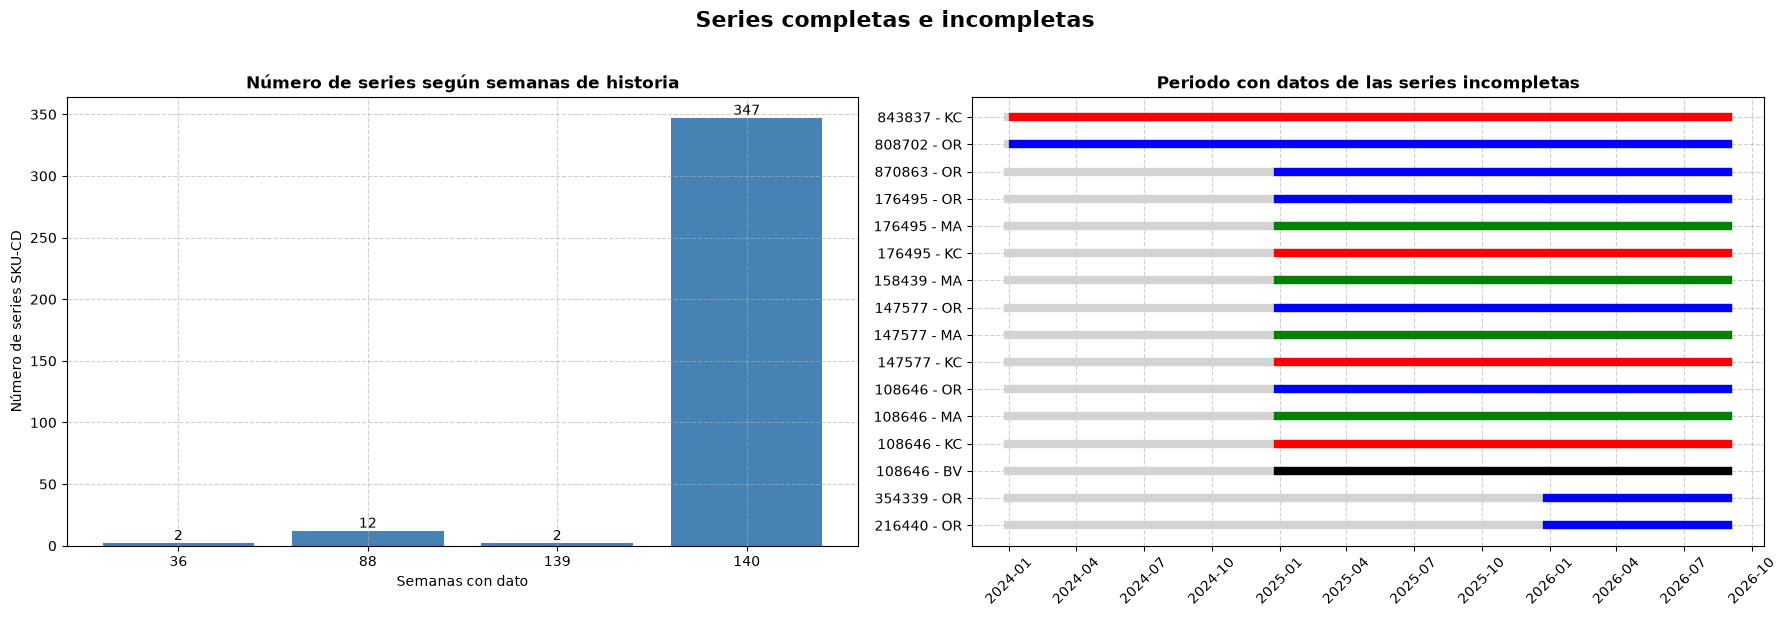

In [107]:
colores_cd = {"BV": "black", "KC": "red", "MA": "green", "OR": "blue"}   # mismos colores por CD
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Número de series según sus semanas de historia
conteo = series_cd["semanas"].value_counts().sort_index()
barras = axes[0].bar(conteo.index.astype(str), conteo.values, color="steelblue")
axes[0].bar_label(barras)
axes[0].set_title("Número de series según semanas de historia", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Semanas con dato")
axes[0].set_ylabel("Número de series SKU-CD")

# Periodo con datos de cada serie incompleta (gris = sin datos)
for i, fila in incompletas.iterrows():
    axes[1].plot([data["ORDER_DATE"].min(), data["ORDER_DATE"].max()], [i, i], color="lightgray", linewidth=6)
    axes[1].plot([fila["inicio"], fila["fin"]], [i, i], color=colores_cd[fila["DC_ID"]], linewidth=6)
axes[1].set_yticks(range(len(incompletas)))
axes[1].set_yticklabels(incompletas["SKU_NBR"].astype(str) + " - " + incompletas["DC_ID"])
axes[1].set_title("Periodo con datos de las series incompletas", fontsize=12, fontweight="bold")
axes[1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))   # un tick por trimestre
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
axes[1].tick_params(axis="x", rotation=45)

# Ajustes estéticos
for ax in axes:
    ax.grid(True, linestyle="--", alpha=0.6)

plt.suptitle("Series completas e incompletas", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

aca solo vemos las series que tenemos completas que tienen datos en las 140 semanas y de las incompletas para ver que todas empiezan tarde y que terminan al tiempo.

### Demanda total del segmento

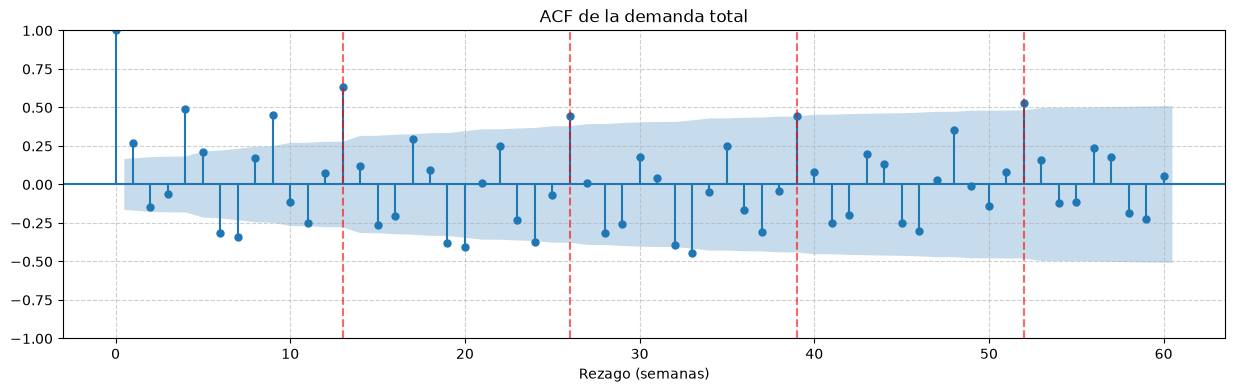

,rezago,acf,significativo
0,4,0.49,True
1,13,0.64,True
2,26,0.45,True
3,39,0.44,True
4,52,0.53,True


In [108]:
# Unidades totales del segmento por semana
total = data.groupby("ORDER_DATE")["ITEMS_QTY"].sum().asfreq("W-SUN")

# ACF del total: un pico en el rezago 13 indica estacionalidad trimestral y en el 52, anual
fig, ax = plt.subplots(figsize=(15, 4))
plot_acf(total, lags=60, ax=ax, title="ACF de la demanda total")
for rezago in [13, 26, 39, 52]:
    ax.axvline(rezago, color="red", linestyle="--", alpha=0.6)   # múltiplos de un trimestre

# Ajustes estéticos
ax.grid(True, linestyle="--", alpha=0.6)
ax.set_xlabel("Rezago (semanas)")
plt.show()

# Valor de la ACF en los rezagos clave y su significancia
acf_total = acf(total, nlags=52)
banda = 1.96 / np.sqrt(len(total))   # límite de la zona sombreada del gráfico
pd.DataFrame({
    "rezago": [4, 13, 26, 39, 52],
    "acf": [round(acf_total[r], 2) for r in [4, 13, 26, 39, 52]],
    "significativo": [abs(acf_total[r]) > banda for r in [4, 13, 26, 39, 52]],
})

como habia estacionalidad aca podemos ver que cada trimestre ahy una estacionalidad (13 semanas) y en cada año tambien (52 semanas)

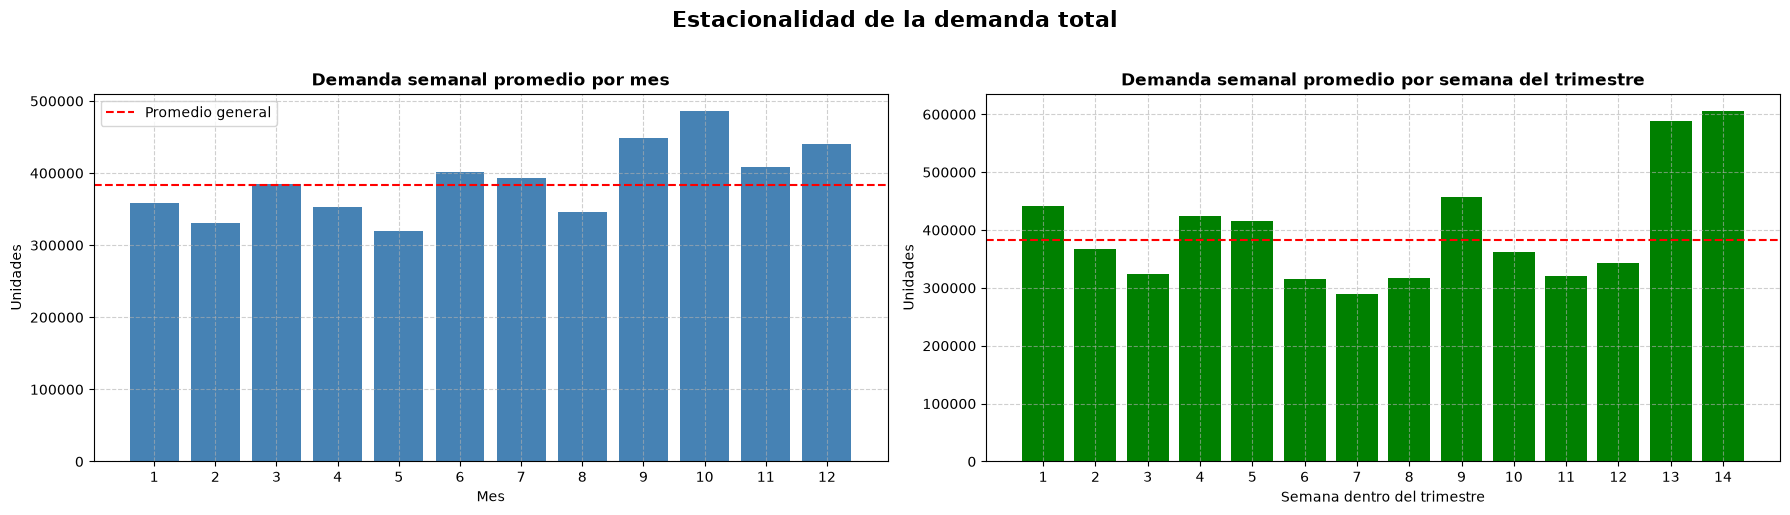

In [109]:
# Demanda promedio por mes del año y por semana dentro del trimestre
total_df = total.to_frame("unidades")
total_df["mes"] = total_df.index.month
inicio_trimestre = total_df.index.to_period("Q").start_time
total_df["semana_trimestre"] = ((total_df.index - inicio_trimestre).days // 7) + 1

por_mes = total_df.groupby("mes")["unidades"].mean()
por_semana_trimestre = total_df.groupby("semana_trimestre")["unidades"].mean()

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

axes[0].bar(por_mes.index, por_mes.values, color="steelblue")
axes[0].axhline(total.mean(), color="red", linestyle="--", label="Promedio general")
axes[0].set_title("Demanda semanal promedio por mes", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Mes")
axes[0].set_xticks(range(1, 13))

axes[1].bar(por_semana_trimestre.index, por_semana_trimestre.values, color="green")
axes[1].axhline(total.mean(), color="red", linestyle="--", label="Promedio general")
axes[1].set_title("Demanda semanal promedio por semana del trimestre", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Semana dentro del trimestre")
axes[1].set_xticks(range(1, 15))

# Ajustes estéticos
for ax in axes:
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.set_ylabel("Unidades")
axes[0].legend()

plt.suptitle("Estacionalidad de la demanda total", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

nos sirve para saber cuando sube la demanda y compararla con los demas meses y tambien para saber como son esos picos en los trimestres

### Demanda por CD

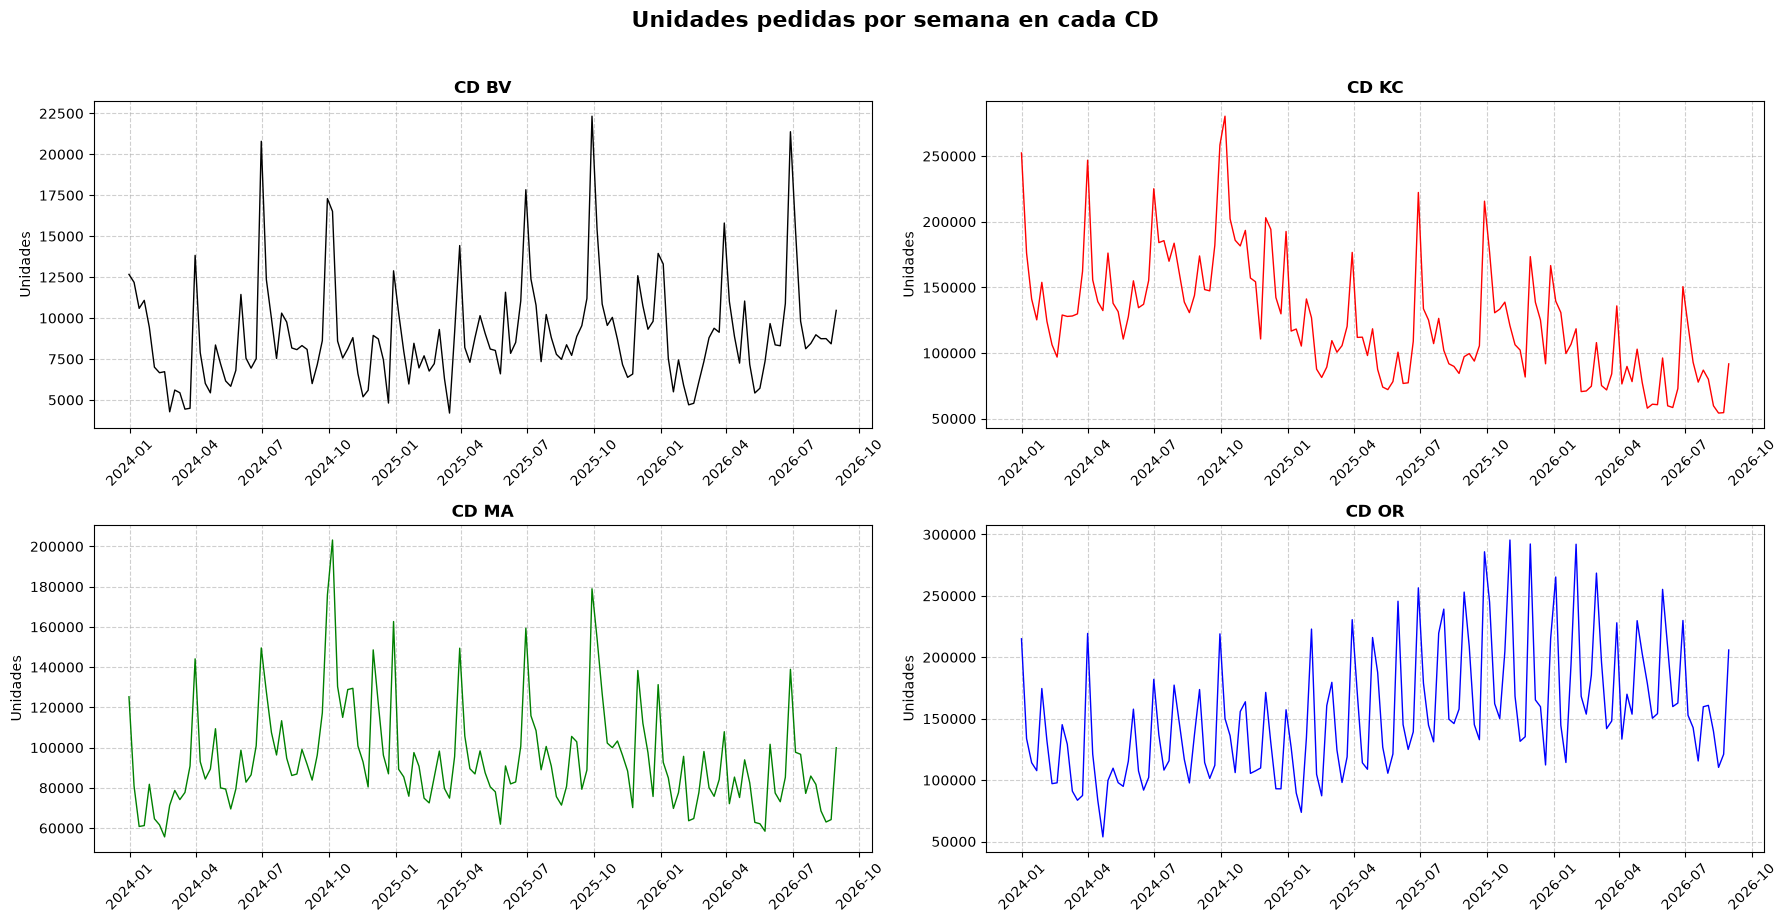

In [110]:
# Unidades por semana en cada CD
por_cd = data.groupby(["ORDER_DATE", "DC_ID"])["ITEMS_QTY"].sum().unstack()

fig, axes = plt.subplots(2, 2, figsize=(18, 9))

for ax, dc in zip(axes.flat, por_cd.columns):
    ax.plot(por_cd[dc], color=colores_cd[dc], linewidth=1)
    ax.set_title(f"CD {dc}", fontsize=12, fontweight="bold")
    ax.set_ylabel("Unidades")

# Ajustes estéticos
for ax in axes.flat:
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))   # un tick por trimestre
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Unidades pedidas por semana en cada CD", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

buscamos entender como funciona cada bodega por separado y si se comportan de manera similar( se ve que todas tienen estacionalidad trimestral

In [111]:
# Resumen de volumen por CD
resumen_cd = (data.groupby("DC_ID")
              .agg(unidades=("ITEMS_QTY", "sum"), skus=("SKU_NBR", "nunique"))
              .sort_values("unidades", ascending=False))
resumen_cd["porcentaje"] = (100 * resumen_cd["unidades"] / resumen_cd["unidades"].sum()).round(1)
resumen_cd["promedio_semanal"] = (resumen_cd["unidades"] / data["ORDER_DATE"].nunique()).round(0)
resumen_cd["promedio_semanal_por_sku"] = (resumen_cd["promedio_semanal"] / resumen_cd["skus"]).round(0)
resumen_cd

,unidades,skus,porcentaje,promedio_semanal,promedio_semanal_por_sku
DC_ID,,,,,
OR,21526431,108,40.2,153760.0,1424.0
KC,17577578,137,32.8,125554.0,916.0
MA,13239778,105,24.7,94570.0,901.0
BV,1260662,13,2.4,9005.0,693.0


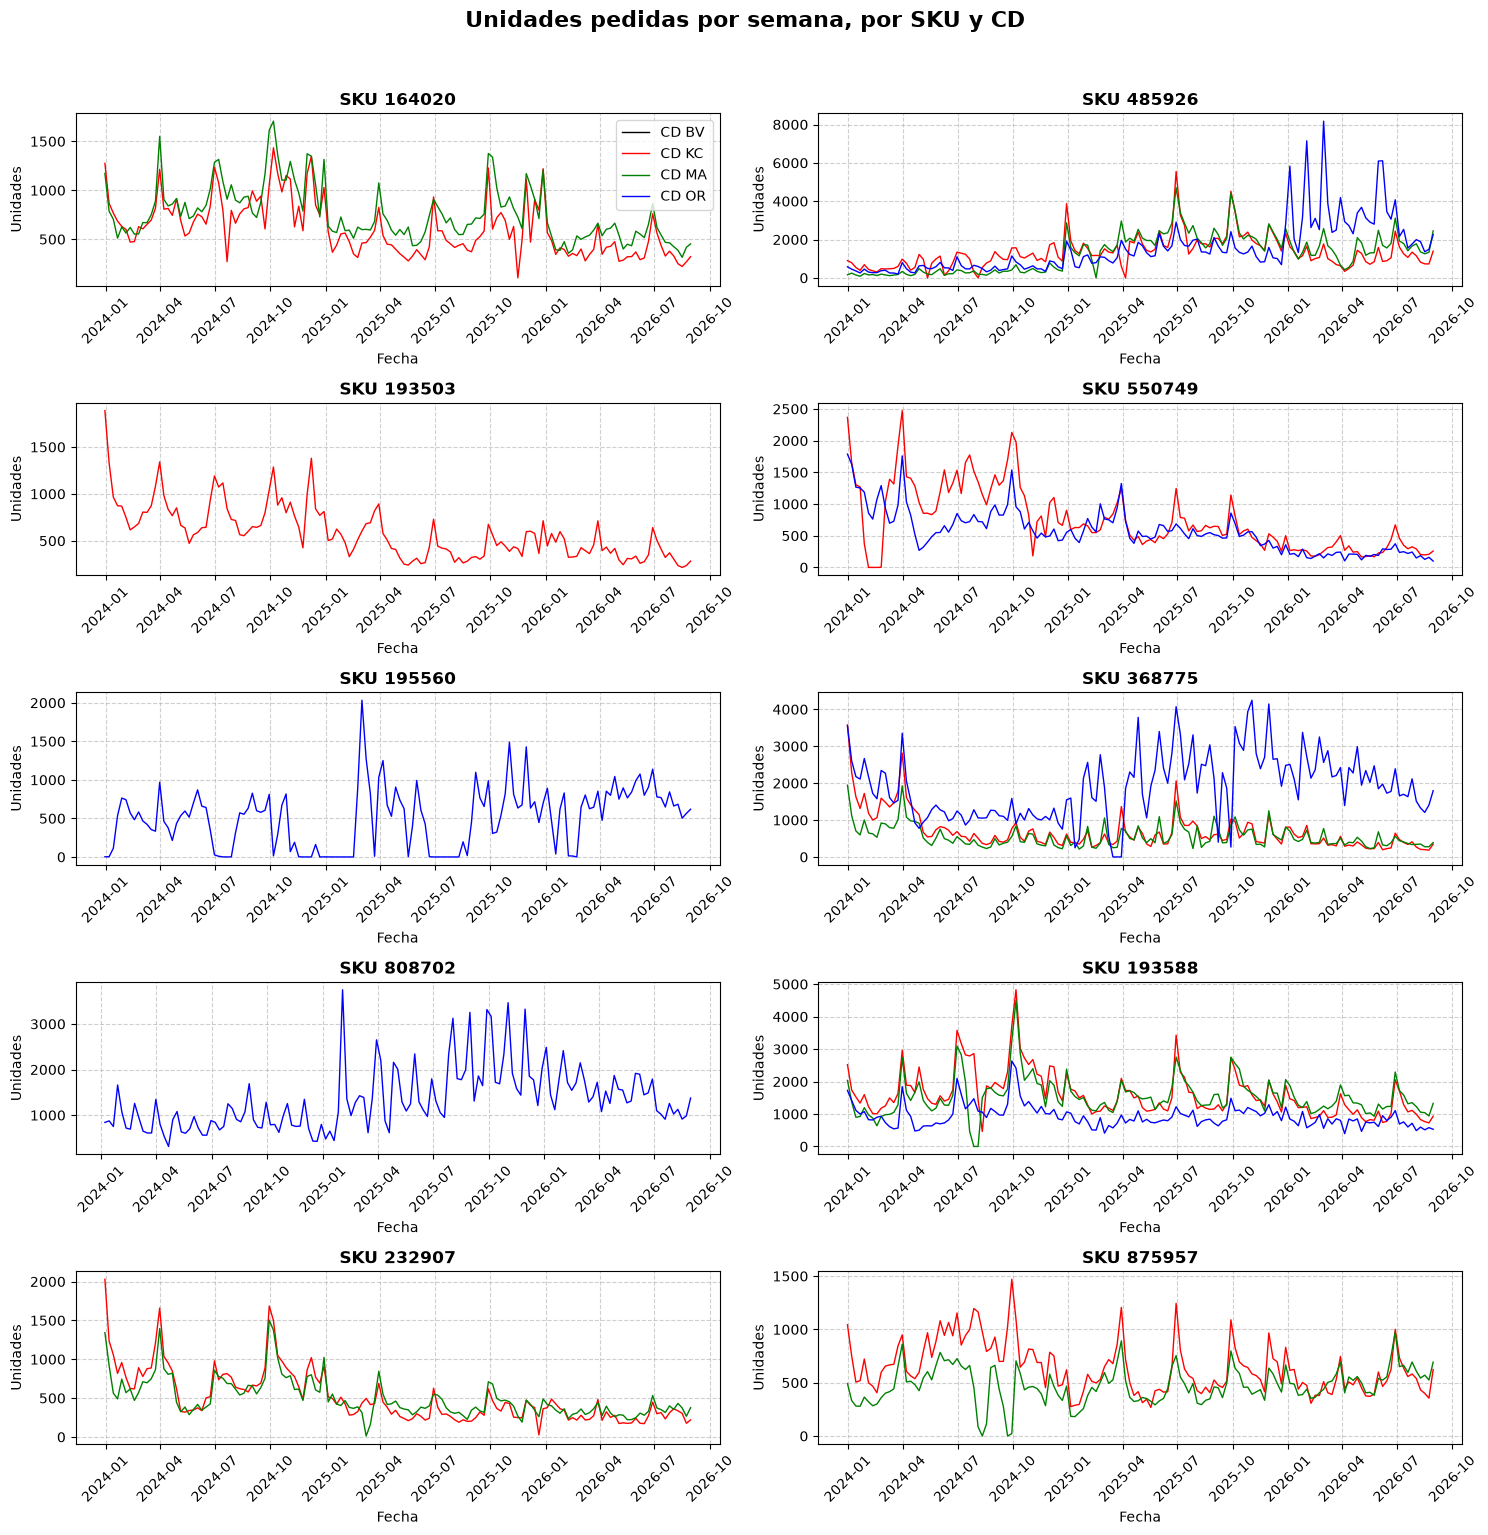

In [112]:
# Unidades por semana, SKU y CD
semanal = (
    data.groupby(["ORDER_DATE", "SKU_NBR", "DC_ID"])
    .agg(ITEMS_QTY=("ITEMS_QTY", "sum"))
    .reset_index()
)

dcs = sorted(data["DC_ID"].unique())
colores = ["black", "red", "green", "blue"]   # un color fijo por CD

# 10 SKUs aleatorios, con semilla fija para que salgan siempre los mismos
top = pd.Series(data["SKU_NBR"].unique()).sample(10, random_state=42)

n = len(top)
fig, axes = plt.subplots(math.ceil(n / 2), 2, figsize=(15, 15))

for ax, sku in zip(axes.flat, top):
    datos_sku = semanal[semanal["SKU_NBR"] == sku]
    for dc, color in zip(dcs, colores):
        serie = (datos_sku[datos_sku["DC_ID"] == dc]
                 .set_index("ORDER_DATE")["ITEMS_QTY"]
                 .asfreq("W-SUN", fill_value=0))
        ax.plot(serie.index, serie.values, color=color, linewidth=1, label=f"CD {dc}")
    ax.set_title(f"SKU {sku}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Fecha")
    ax.set_ylabel("Unidades")

    # Un tick por trimestre: enero, abril, julio, octubre
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.tick_params(axis="x", rotation=45)

# Ajustes estéticos
for ax in axes.flat:
    ax.grid(True, linestyle="--", alpha=0.6)
axes.flat[0].legend()

plt.suptitle("Unidades pedidas por semana, por SKU y CD", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

buscamos ver como se ven los productos por bodega

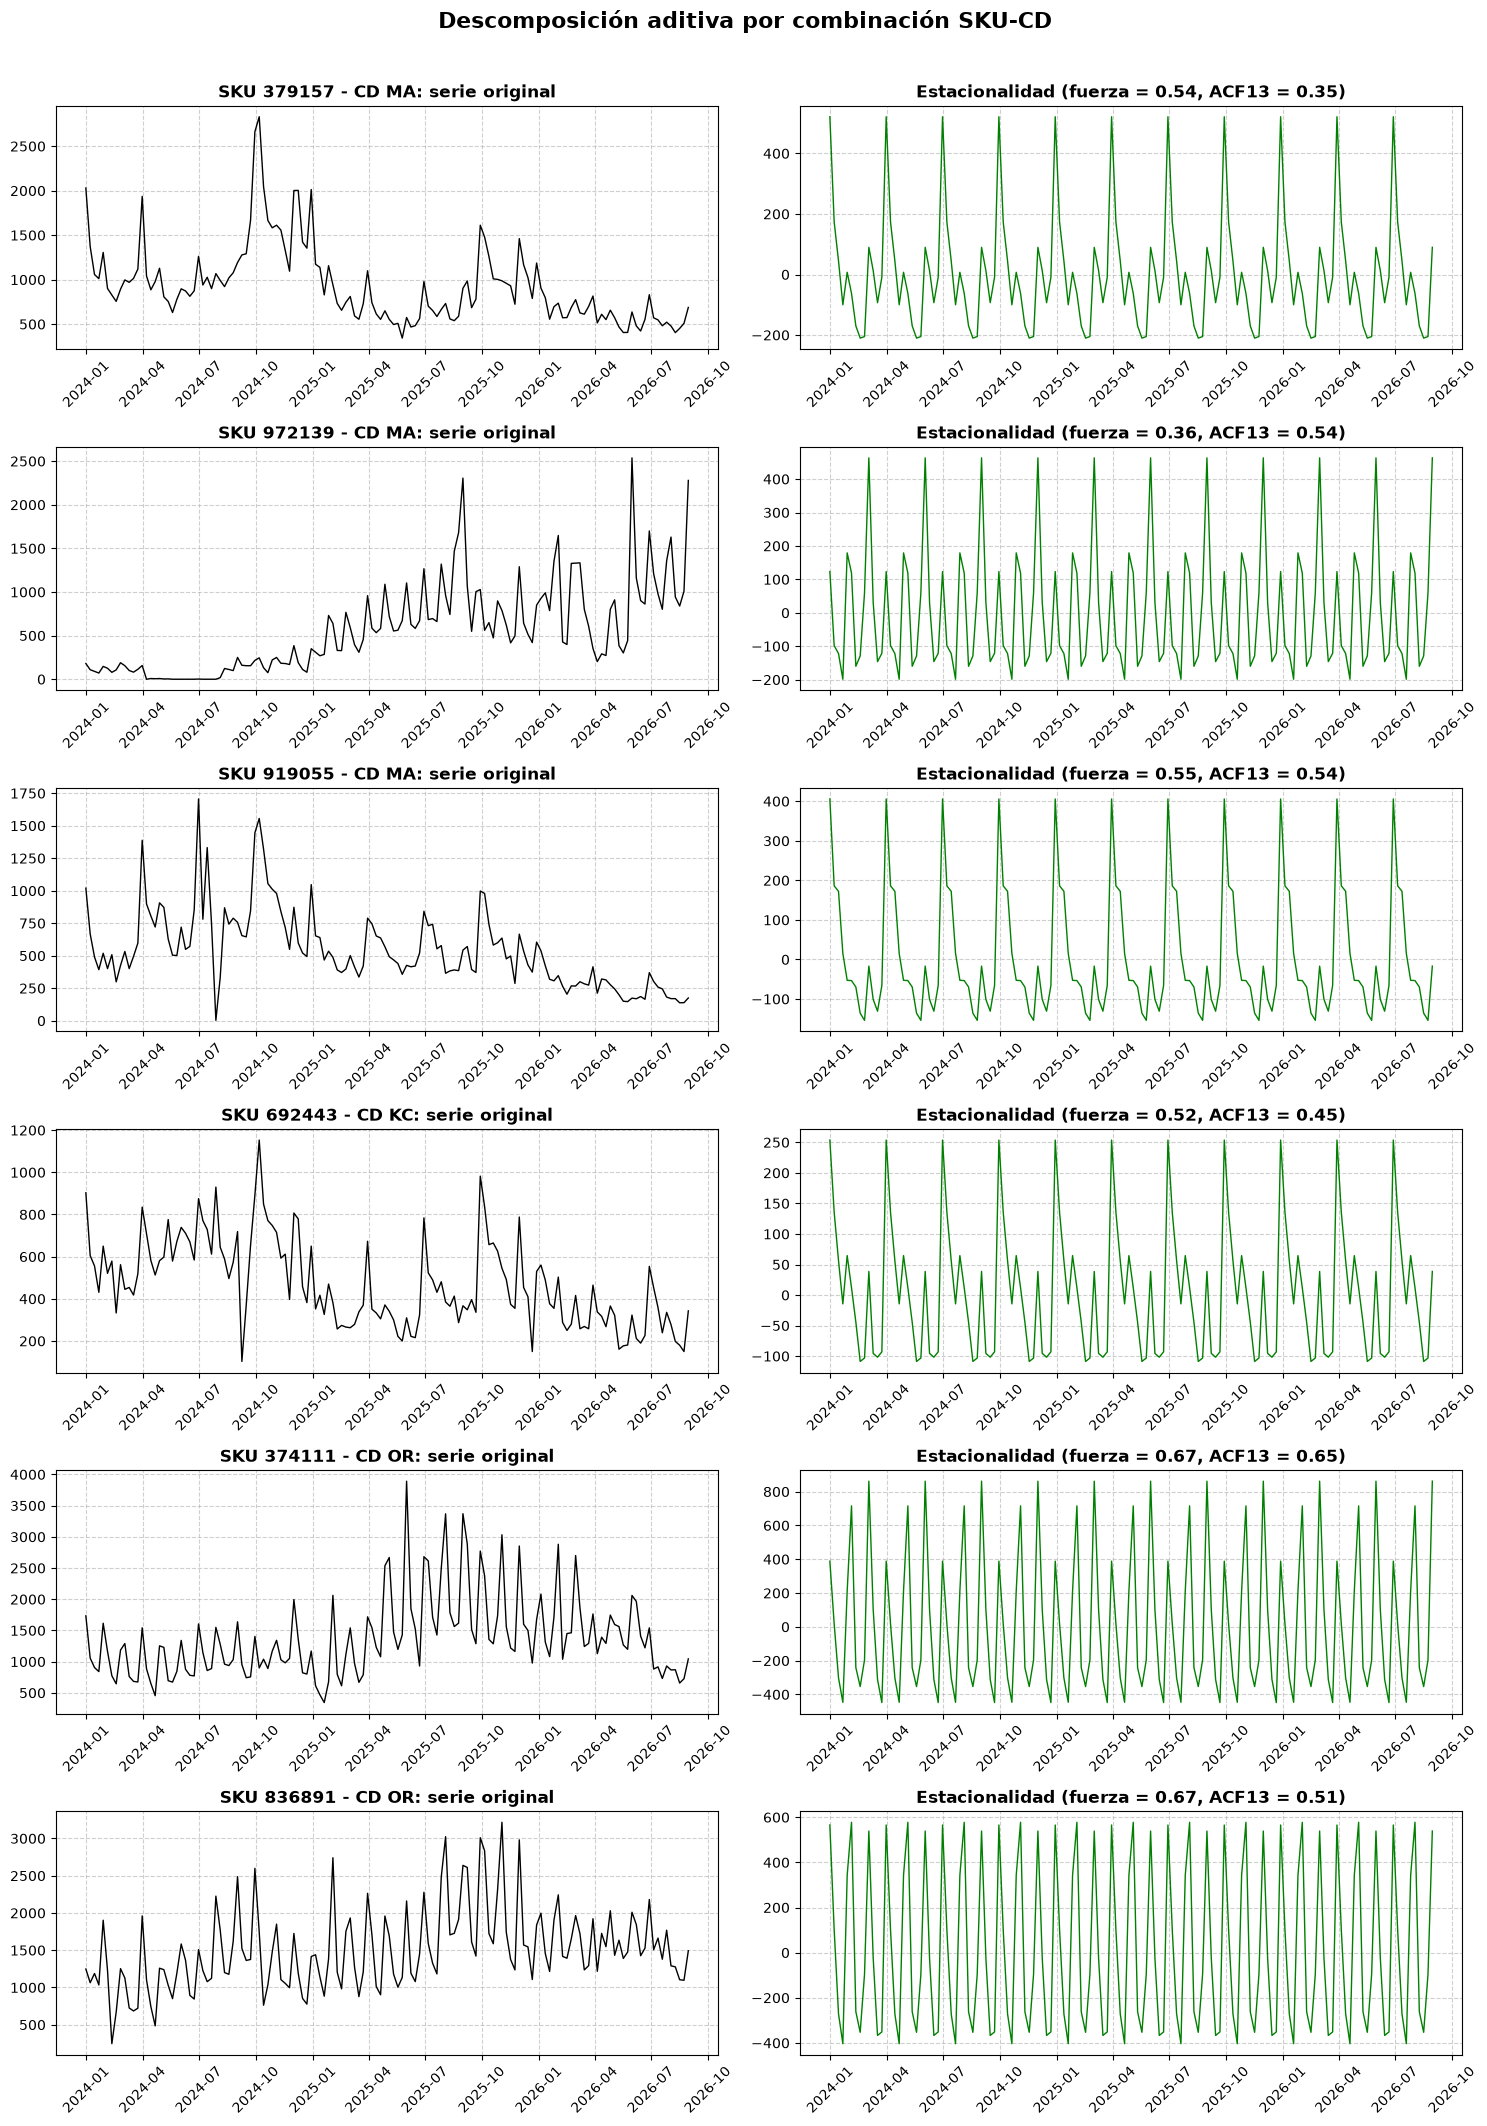

,SKU_NBR,DC_ID,semanas,fuerza_estacional,acf_13,acf_13_significativo
4,374111,OR,140,0.67,0.65,True
5,836891,OR,140,0.67,0.51,True
2,919055,MA,140,0.55,0.54,True
0,379157,MA,140,0.54,0.35,True
3,692443,KC,140,0.52,0.45,True
1,972139,MA,140,0.36,0.54,True


In [113]:
# Parejas SKU-CD que existen y tienen al menos 2 años de historia
parejas = (semanal.groupby(["SKU_NBR", "DC_ID"])["ORDER_DATE"]
           .agg(inicio="min", fin="max")
           .reset_index())
parejas["semanas"] = ((parejas["fin"] - parejas["inicio"]).dt.days // 7) + 1
validas = parejas[parejas["semanas"] >= 104]

n = 6
muestra = validas.sample(n, random_state=42)   # semilla fija: siempre las mismas series

fig, axes = plt.subplots(n, 2, figsize=(15, 3.5 * n))
resultados = []

for i, (_, fila) in enumerate(muestra.iterrows()):
    sku, dc = fila["SKU_NBR"], fila["DC_ID"]

    serie = (semanal[(semanal["SKU_NBR"] == sku) & (semanal["DC_ID"] == dc)]
             .set_index("ORDER_DATE")["ITEMS_QTY"]
             .asfreq("W-SUN", fill_value=0))

    decomp = seasonal_decompose(serie, model="additive", period=13)   # 13 semanas = 1 trimestre

    # Fuerza de la estacionalidad: 0 = nada, cerca de 1 = muy fuerte
    s, r = decomp.seasonal, decomp.resid.dropna()
    fuerza = max(0, 1 - r.var() / (s.loc[r.index] + r).var())

    # ACF en el rezago 13 y su significancia
    acf_vals = acf(serie, nlags=26)
    banda = 1.96 / np.sqrt(len(serie))   # límite de la zona sombreada del gráfico

    resultados.append({
        "SKU_NBR": sku,
        "DC_ID": dc,
        "semanas": len(serie),
        "fuerza_estacional": round(fuerza, 2),
        "acf_13": round(acf_vals[13], 2),
        "acf_13_significativo": abs(acf_vals[13]) > banda,
    })

    # Serie original
    axes[i, 0].plot(serie, color="black", linewidth=1)
    axes[i, 0].set_title(f"SKU {sku} - CD {dc}: serie original", fontsize=12, fontweight="bold")

    # Estacionalidad
    axes[i, 1].plot(decomp.seasonal, color="green", linewidth=1)
    axes[i, 1].set_title(f"Estacionalidad (fuerza = {fuerza:.2f}, ACF13 = {acf_vals[13]:.2f})",
                         fontsize=12, fontweight="bold")

# Ajustes estéticos
for ax in axes.flat:
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))   # un tick por trimestre
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Descomposición aditiva por combinación SKU-CD", fontsize=16, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# Resumen
resumen = pd.DataFrame(resultados).sort_values("fuerza_estacional", ascending=False)
resumen

aca simplemente es para ver si la estacionalidad es trimestrar en cada serie  y para saber si el patron es fuerte o debil en las series

### Nulos, duplicados y negativos

In [114]:
# Revisión básica de calidad de los datos
print("Nulos por columna:")
print(data.isnull().sum())
print("\nFilas duplicadas (misma semana, SKU y CD):", data.duplicated(["ORDER_DATE", "SKU_NBR", "DC_ID"]).sum())
print("Cantidades negativas:", (data["ITEMS_QTY"] < 0).sum())
print("Fechas que no caen en domingo:", (data["ORDER_DATE"].dt.dayofweek != 6).sum())

Nulos por columna:
DC_ID         0
SKU_NBR       0
ORDER_DATE    0
ITEMS_QTY     0
dtype: int64

Filas duplicadas (misma semana, SKU y CD): 0
Cantidades negativas: 0
Fechas que no caen en domingo: 0


aca es solo para saber si tenemos nulos, y pues no hay y pasa lo mismo con los repetidos y negativos que tampoco hay

### Ceros

In [115]:
# Racha más larga de semanas seguidas en cero dentro de una serie
def racha_ceros(serie):
    es_cero = serie.eq(0)
    bloques = (es_cero != es_cero.shift()).cumsum()   # cada cambio entre cero y no cero abre un bloque nuevo
    return es_cero.groupby(bloques).sum().max()

# Ceros por serie SKU-CD
ceros = (data.sort_values("ORDER_DATE")
         .groupby(["SKU_NBR", "DC_ID"])["ITEMS_QTY"]
         .agg(semanas="count", ceros=lambda x: (x == 0).sum(), racha_maxima=racha_ceros)
         .reset_index())
ceros["porcentaje_ceros"] = (100 * ceros["ceros"] / ceros["semanas"]).round(1)

print("Semanas en cero en todo el panel:", ceros["ceros"].sum(), f"({100 * ceros['ceros'].sum() / len(data):.1f}% de las filas)")
print("Series con al menos un cero:", (ceros["ceros"] > 0).sum(), "de", len(ceros))
print("Series con más del 20% de semanas en cero:", (ceros["porcentaje_ceros"] > 20).sum())
print("Series con 4 o más semanas seguidas en cero:", (ceros["racha_maxima"] >= 4).sum())
print("Series con 8 o más semanas seguidas en cero:", (ceros["racha_maxima"] >= 8).sum())

# Series con más ceros
ceros.sort_values("porcentaje_ceros", ascending=False).head(10)

Semanas en cero en todo el panel: 879 (1.8% de las filas)
Series con al menos un cero: 145 de 363
Series con más del 20% de semanas en cero: 2
Series con 4 o más semanas seguidas en cero: 49
Series con 8 o más semanas seguidas en cero: 25


,SKU_NBR,DC_ID,semanas,ceros,racha_maxima,porcentaje_ceros
33,171322,KC,140,39,12,27.9
317,887910,OR,140,29,16,20.7
294,843837,OR,140,28,8,20.0
4,108646,BV,88,16,7,18.2
292,843837,KC,139,24,9,17.3
316,887910,KC,140,23,4,16.4
282,836320,KC,140,20,7,14.3
44,195560,OR,140,20,7,14.3
293,843837,MA,140,17,10,12.1
252,700135,KC,140,16,10,11.4


sola,ente es para identificar cuanros seros hay pero y pensar en como tratarlos

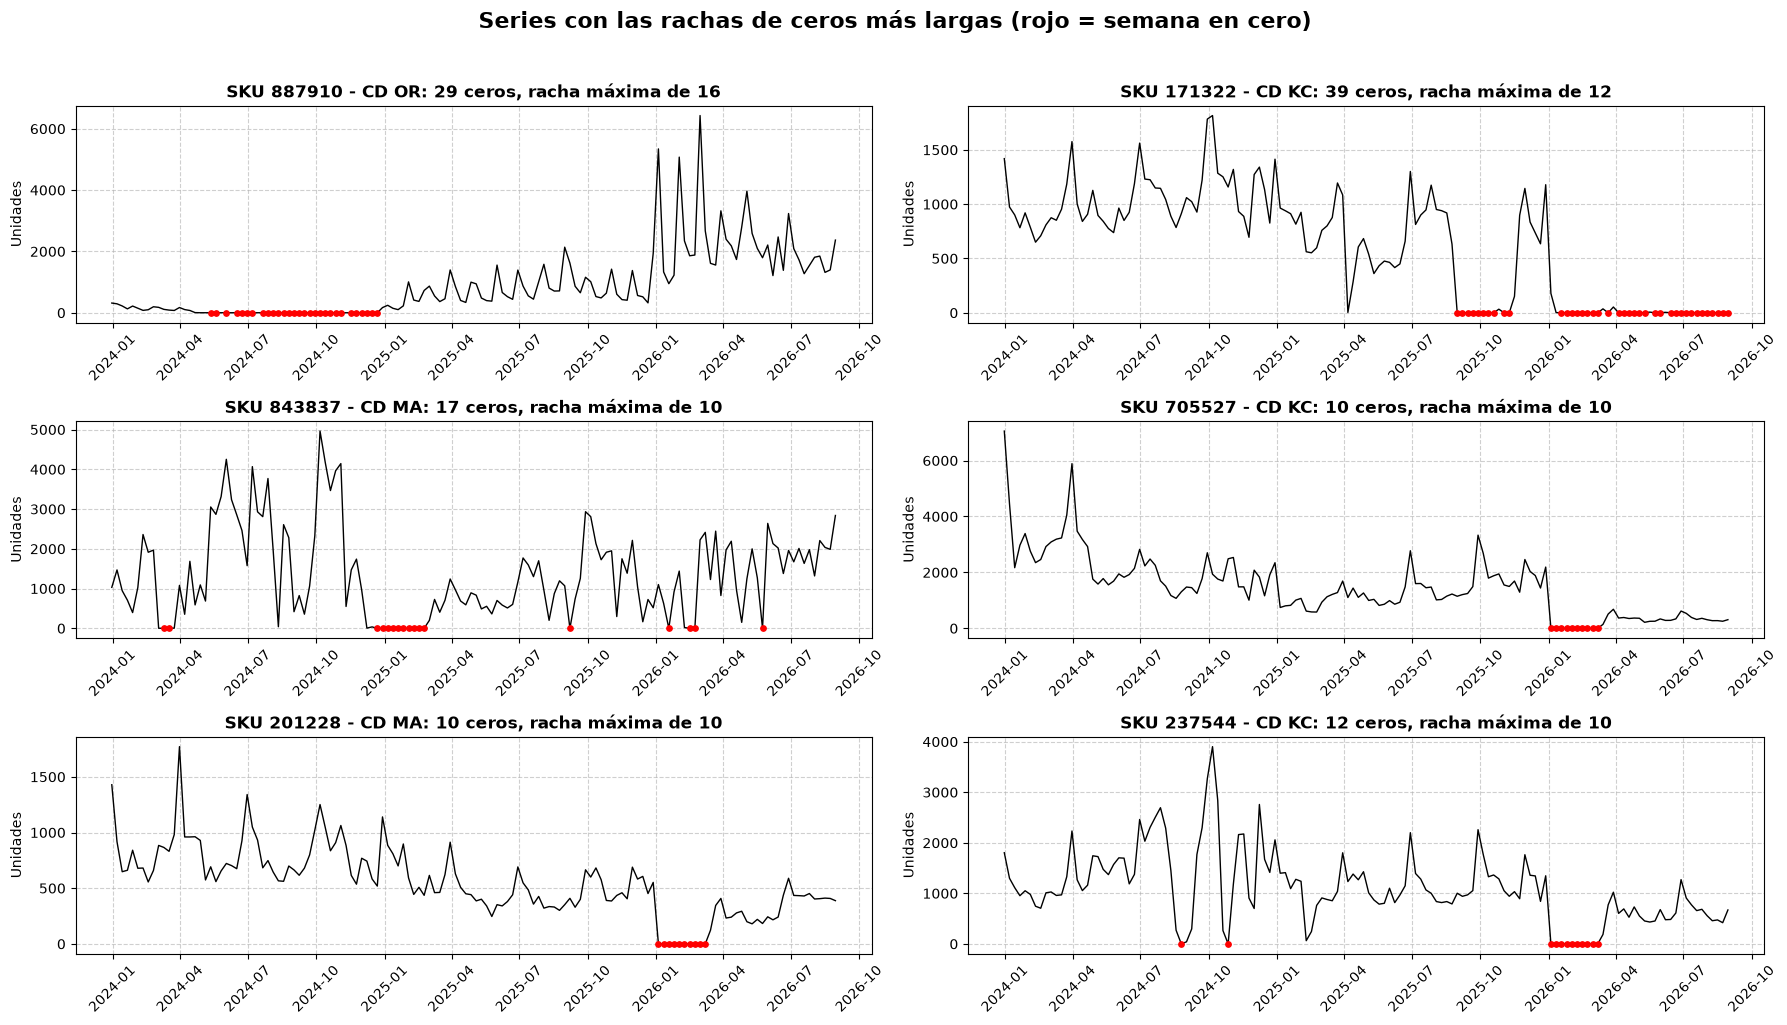

In [116]:
# Las 6 series con la racha de ceros más larga, marcando en rojo las semanas en cero
peores = ceros.sort_values("racha_maxima", ascending=False).head(6)

fig, axes = plt.subplots(3, 2, figsize=(18, 10))

for ax, (_, fila) in zip(axes.flat, peores.iterrows()):
    serie = (data[(data["SKU_NBR"] == fila["SKU_NBR"]) & (data["DC_ID"] == fila["DC_ID"])]
             .set_index("ORDER_DATE")["ITEMS_QTY"]
             .sort_index())
    ax.plot(serie, color="black", linewidth=1)
    ax.scatter(serie[serie == 0].index, serie[serie == 0], color="red", s=15, zorder=3)
    ax.set_title(f"SKU {fila['SKU_NBR']} - CD {fila['DC_ID']}: {fila['ceros']} ceros, racha máxima de {fila['racha_maxima']}",
                 fontsize=12, fontweight="bold")
    ax.set_ylabel("Unidades")

# Ajustes estéticos
for ax in axes.flat:
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))   # un tick por trimestre
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Series con las rachas de ceros más largas (rojo = semana en cero)", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

aca quisimos ver cuales series son las que tienen mas ceros seguidos para identificar como se comportan esos seros si es que el producto no se vende en esa epoca o si ya no hay

### Atípicos

In [117]:
atipicos = data.copy()
atipicos["z"] = (atipicos.groupby(["SKU_NBR", "DC_ID"])["ITEMS_QTY"]
                 .transform(lambda x: (x - x.mean()) / x.std()))
atipicos["atipico"] = atipicos["z"].abs() > 3

inicio_trim = atipicos["ORDER_DATE"].dt.to_period("Q").dt.start_time
atipicos["semana_trimestre"] = ((atipicos["ORDER_DATE"] - inicio_trim).dt.days // 7) + 1

print("Semanas atípicas:", atipicos["atipico"].sum(), f"({100 * atipicos['atipico'].mean():.1f}% de las filas)")
print("  - Por encima (picos):", (atipicos["z"] > 3).sum())
print("  - Por debajo (caídas):", (atipicos["z"] < -3).sum())
print("Atípicos en las semanas 1, 13 y 14 del trimestre:", f"{100 * atipicos[atipicos['atipico']]['semana_trimestre'].isin([1, 13, 14]).mean():.1f}%",
      f"(esas semanas son solo el {100 * atipicos['semana_trimestre'].isin([1, 13, 14]).mean():.1f}% del total)")
print("Series con al menos un atípico:", atipicos[atipicos["atipico"]].groupby(["SKU_NBR", "DC_ID"]).ngroups, "de", len(ceros))

Semanas atípicas: 633 (1.3% de las filas)
  - Por encima (picos): 632
  - Por debajo (caídas): 1
Atípicos en las semanas 1, 13 y 14 del trimestre: 81.4% (esas semanas son solo el 15.7% del total)
Series con al menos un atípico: 311 de 363


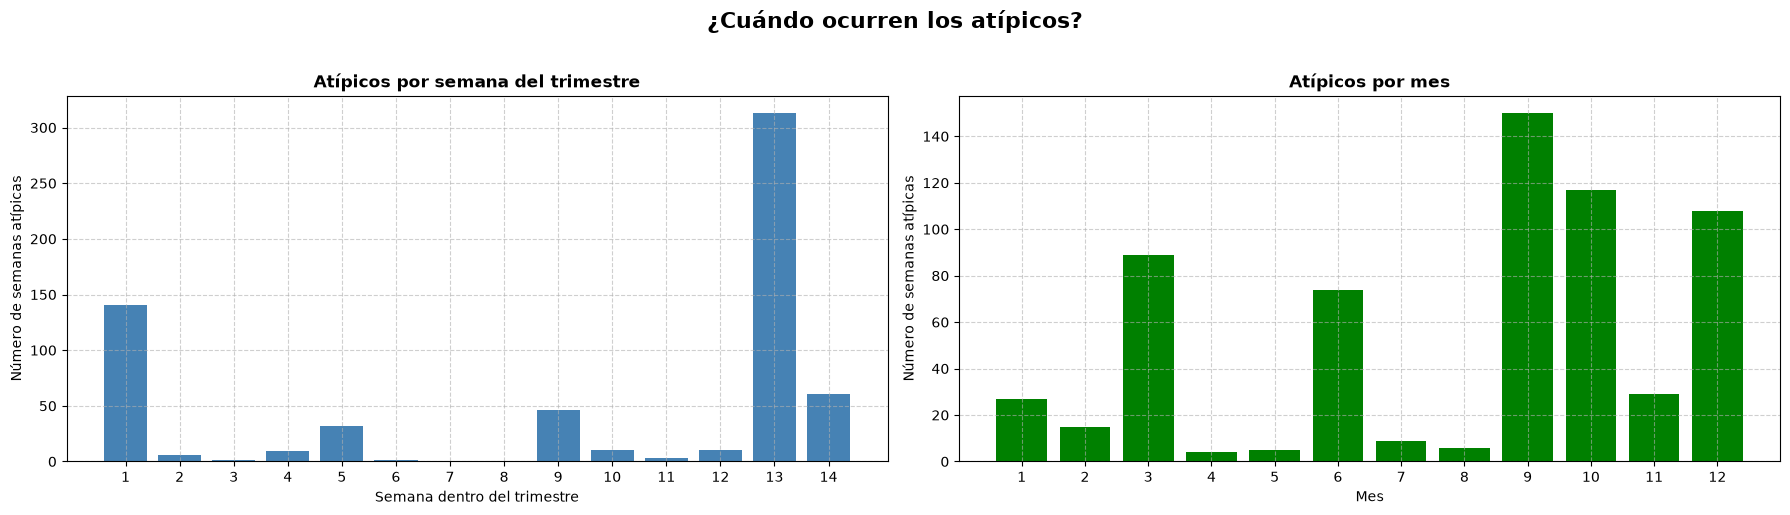

In [118]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# En qué semana del trimestre caen los atípicos
por_semana = atipicos[atipicos["atipico"]]["semana_trimestre"].value_counts().sort_index()
axes[0].bar(por_semana.index, por_semana.values, color="steelblue")
axes[0].set_title("Atípicos por semana del trimestre", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Semana dentro del trimestre")
axes[0].set_ylabel("Número de semanas atípicas")
axes[0].set_xticks(range(1, 15))

# En qué mes caen los atípicos
por_mes_atip = atipicos[atipicos["atipico"]]["ORDER_DATE"].dt.month.value_counts().sort_index()
axes[1].bar(por_mes_atip.index, por_mes_atip.values, color="green")
axes[1].set_title("Atípicos por mes", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Mes")
axes[1].set_ylabel("Número de semanas atípicas")
axes[1].set_xticks(range(1, 13))

# Ajustes estéticos
for ax in axes:
    ax.grid(True, linestyle="--", alpha=0.6)

plt.suptitle("¿Cuándo ocurren los atípicos?", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

buscamos ver como se comportan los datos atipicos y ver en que semanas caen y obtuvimos que principamente caen en esos trimentres y en la ukltima y primera semana que son casi siempre donde esta el pico

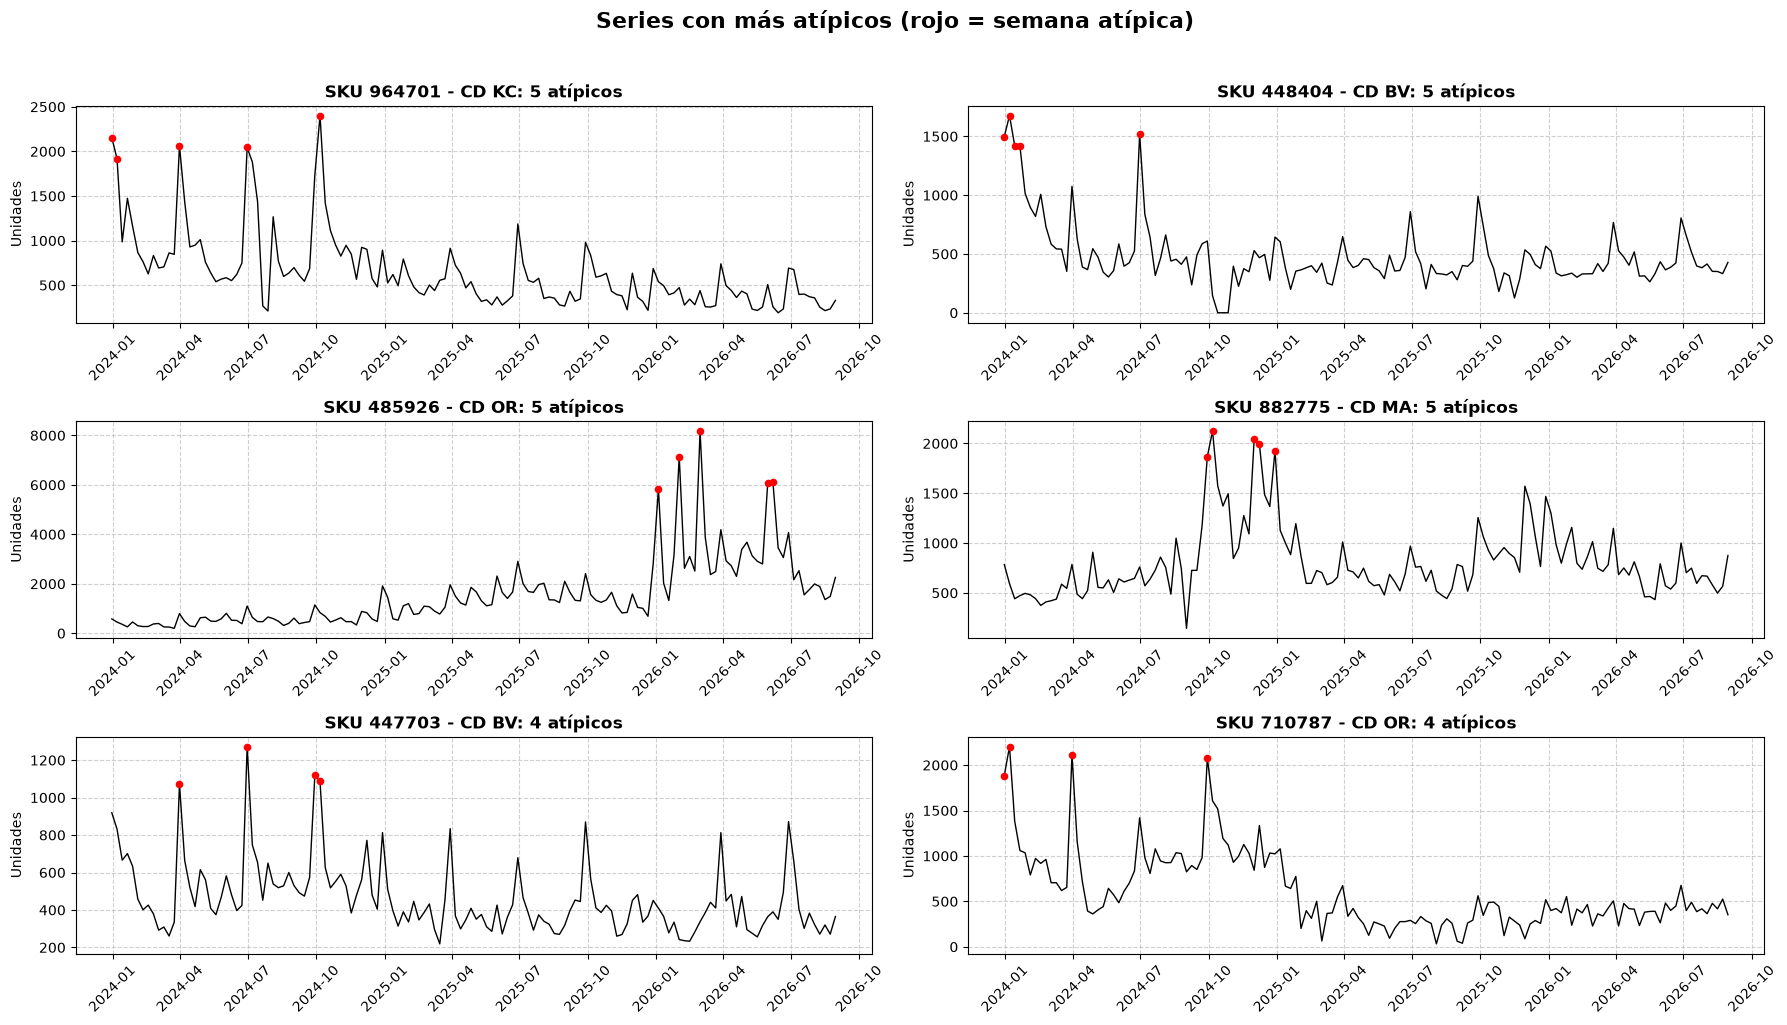

In [119]:
# 6 series con más atípicos, marcando en rojo las semanas atípicas
mas_atipicos = (atipicos[atipicos["atipico"]]
                .groupby(["SKU_NBR", "DC_ID"]).size()
                .sort_values(ascending=False)
                .head(6))

fig, axes = plt.subplots(3, 2, figsize=(18, 10))

for ax, ((sku, dc), n_atip) in zip(axes.flat, mas_atipicos.items()):
    serie = (atipicos[(atipicos["SKU_NBR"] == sku) & (atipicos["DC_ID"] == dc)]
             .set_index("ORDER_DATE")
             .sort_index())
    ax.plot(serie["ITEMS_QTY"], color="black", linewidth=1)
    ax.scatter(serie[serie["atipico"]].index, serie[serie["atipico"]]["ITEMS_QTY"], color="red", s=20, zorder=3)
    ax.set_title(f"SKU {sku} - CD {dc}: {n_atip} atípicos", fontsize=12, fontweight="bold")
    ax.set_ylabel("Unidades")

# Ajustes estéticos
for ax in axes.flat:
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))   # un tick por trimestre
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Series con más atípicos (rojo = semana atípica)", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### Conclusiones

Simplemente pudimos ver como estan los productos ubicados en las bodegas de la farmacia y pues que tenemos 363 series para que podamos tipo predecir tambien pudimos ver que casi todas esas estan completas y tambien que ya estan  full limpios y tipo hay cero nulos repetidos y negativos, de los datos asi como venian lo unico que tuvimos que moverle fue pasar la fecha a datetime y ya, lo otro fue que nos dimos cuenta que la estacionalidad es en cada trimestre y en cada año en el grafico de Estacionalidad de la demanda total vimos que hay unos meses en donde se piden muchso mas productos y que las bodegas no son iguales  al igual que los productos como que el comportamiento son super diferentes. tambien pudimos ver como que los ceros solo es que no se pidieron productos y quisimos dejarlos asi porque solo son semanas donde no pidieron nada y pues como tambien hay unas en donde no hay al inicio es como porque no tenian productos entonces para no inventar nada lo dejamos asi, para el tema de los atipicos si es solo los picos grandes donde piden muchisimos productos que es siempre en los cierres de trimestres entonces no son errores ni nada por el estilo y pues si los quitamos el modelo no va a pronosticar bien todo y ya

## Punto 2

**Modelo base, métrica y separación temporal**  
Implementen **al menos dos modelos base**: **Naive** (última semana, o *seasonal naive*), **Media móvil** y **SARIMA**. Definan una separación entrenamiento/prueba que respete la temporalidad y que tenga como prueba **al menos un trimestre calendario completo** (13 semanas), sin fuga de información. Evalúen con métricas coherentes con el negocio en dos niveles:

In [120]:
# Una serie por pareja SKU-CD, solo las que tienen historia suficiente
series = semanal.merge(validas[["SKU_NBR", "DC_ID"]], on=["SKU_NBR", "DC_ID"])
series["item_id"] = series["SKU_NBR"].astype(str) + "_" + series["DC_ID"].astype(str)

# Rellenar semanas sin pedidos dentro del periodo activo de cada serie
series = (series.set_index("ORDER_DATE")
          .groupby("item_id")["ITEMS_QTY"]
          .apply(lambda s: s.asfreq("W-SUN", fill_value=0))
          .reset_index()
          .rename(columns={"ORDER_DATE": "timestamp", "ITEMS_QTY": "target"}))

test_data = TimeSeriesDataFrame.from_data_frame(series, id_column="item_id", timestamp_column="timestamp")

prediction_length = 13   # un trimestre
train_data = test_data.slice_by_timestep(None, -prediction_length)

print(f"Series: {train_data.num_items}")
print(f"Semanas por serie en train (mín.): {train_data.num_timesteps_per_item().min()}")
print(f"Semanas por serie en test  (mín.): {test_data.num_timesteps_per_item().min()}")

Series: 349
Semanas por serie en train (mín.): 126
Semanas por serie en test  (mín.): 139


solo armamos los datos para que quede con el sku del producto y el cd tambien separamos las ultimas 13 semanas para que probemos con esas y entrenar con todas las anteriores

In [121]:
predictor = TimeSeriesPredictor(
    prediction_length=prediction_length,
    target="target",
    eval_metric="MASE",
)

predictor.fit(
    train_data,
    hyperparameters={
        "AutoARIMA": {"season_length": 13, "max_d": 1, "max_D": 1},   # SARIMA, uno por serie
    },
    enable_ensemble=False,
)

predictor.leaderboard(test_data, extra_metrics=["MAE", "RMSE", "MAPE", "WAPE"])

Beginning AutoGluon training...
AutoGluon will save models to '/Users/teo/Documents/Parcial-Forecasting/AutogluonModels/ag-20261019_123809'
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.12.14
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 25.6.0: Fri Jul 31 19:16:20 PDT 2026; root:xnu-12377.161.14~5/RELEASE_ARM64_T8142
CPU Count:          10
Pytorch Version:    2.10.0
CUDA Version:       CUDA is not available
GPU Count:          WARNING: Exception was raised when calculating GPU count (AssertionError)
Memory Avail:       6.07 GB / 24.00 GB (25.3%)
Disk Space Avail:   74.61 GB / 460.38 GB (16.2%)

Fitting with arguments:
{'enable_ensemble': False,
 'eval_metric': MASE,
 'hyperparameters': {'AutoARIMA': {'max_D': 1,
                                   'max_d': 1,
                                   'season_length': 13}},
 'known_covariates_names': [],
 'num_val_windows': 1,
 'prediction_le

,model,score_test,score_val,pred_time_test,pred_time_val,fit_time_marginal,fit_order,MAE,RMSE,MAPE,WAPE
0,AutoARIMA,-0.896051,-1.073613,10.450668,21.93073,0.019499,1,-352.519956,-1084.041867,-2.231381,-0.390042


ahora vamos es nomas a entrenar el modelo, le pusimos esa estacionalidad de 3 meses pero igual no hizo nada, y ver como quedan las metricas

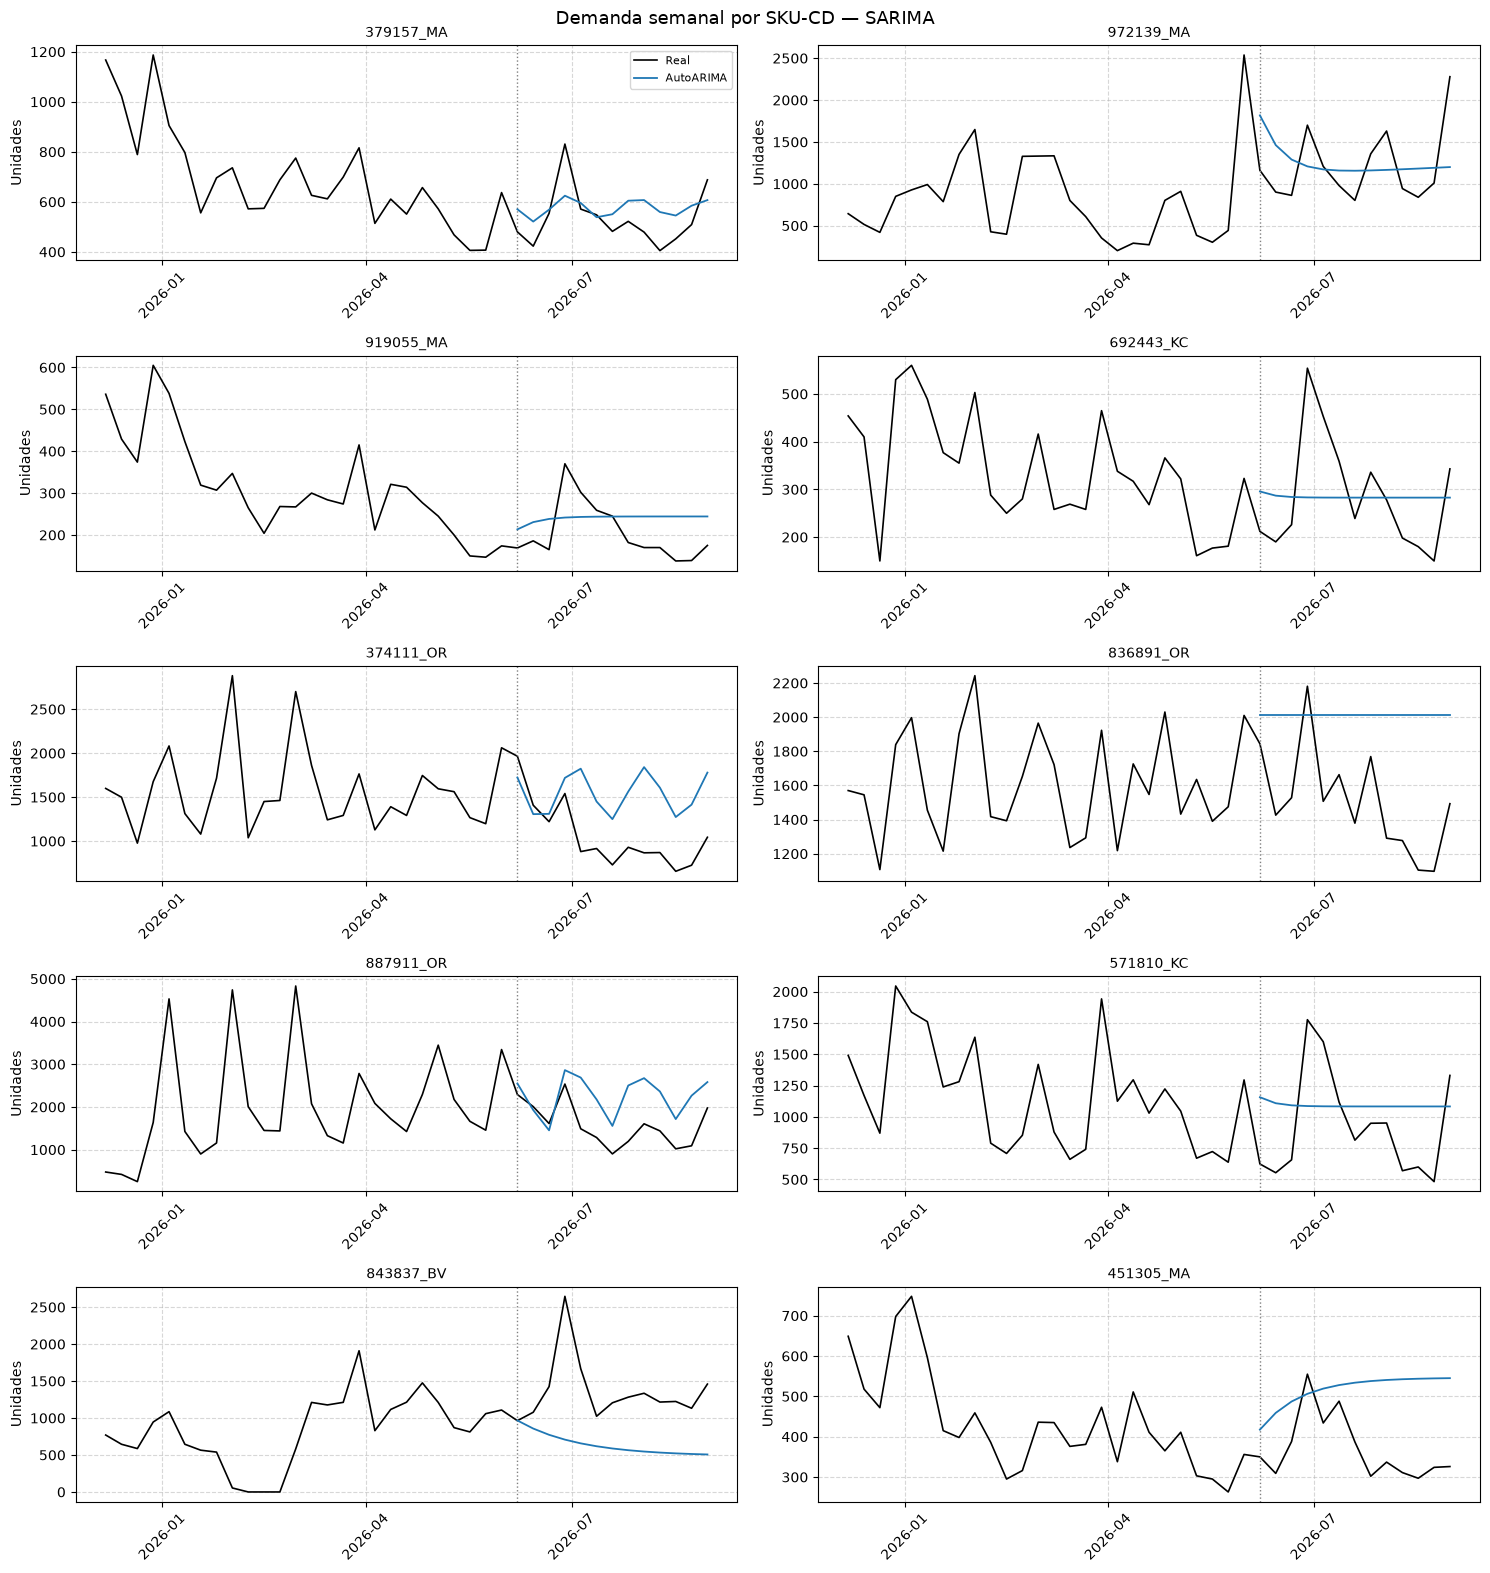

In [122]:
series_muestra = pd.Series(test_data.item_ids).sample(10, random_state=42).values

graficar_comparacion(
    predictor, train_data, test_data,
    item_ids=series_muestra,
    historia=prediction_length * 2,
    #modelo_intervalo="AutoARIMA",
    titulo="Demanda semanal por SKU-CD — SARIMA",
)

ahora vamos a ver como se predijo el modelo y pues vemos que esta horrible literal y que predice super mal osea llega a ser hasta plano a veces y no sigue la estacionalidad

### Conclusiones

nos dimos cuenta que Sarima como modelo base no predice para nada bien y se equivoca casi en un 40% en el WAPE, tambien nos dimos cuenta que queda casi plano ese pronostico y que no tiene en cuenta los trimestres de la estacionalidad que habiamos visto en los datos entonces pues toca ver con un modelo mas avanzado

## Punto 3

**Pool de modelos para mejorar el modelo base**  
Construyan un **pool de al menos tres modelos avanzados** y comparen su desempeño contra el benchmark, usando **la misma ventana de evaluación y las mismas métricas**. Algunas opciones:
   - **Prophet** (con estacionalidades y/o festivos de EE. UU.).
   - **Nixtla**: `statsforecast` (AutoETS, AutoARIMA, MSTL, Croston/TSB para demanda intermitente), `mlforecast` (LightGBM/XGBoost con rezagos y variables de calendario), `neuralforecast` (NHITS, NBEATS, etc.) o TimeGPT.
   - **Chronos** (Amazon) u otros modelos fundacionales para series de tiempo.
   
   Presenten una tabla comparativa con todos los modelos (base y avanzados), justifiquen la elección de cada uno y analicen dónde mejora cada modelo y dónde no (por CD, por volumen del SKU, por tipo de serie). Se valora usar validación con origen móvil (*rolling forecast*) sobre varios trimestres.

entonces como necesitamos un modelo mas avanzado vamos a aprovechar que ya utilizamos zero shot de amazon chronos para la expo y vamos a usar este a ver si le gana a las metricas de Sarima

In [123]:
predictor = TimeSeriesPredictor(
    prediction_length=prediction_length,
    target="target",
    eval_metric="MASE",
)

predictor.fit(
    train_data,
    hyperparameters={
        "AutoARIMA": {"season_length": 13, "max_d": 1, "max_D": 1},   # SARIMA, uno por serie
        "Chronos": {"model_path": "bolt_small", "ag_args": {"name_suffix": "ZeroShot"}},
    },
    enable_ensemble=False,
)

predictor.leaderboard(test_data, extra_metrics=["MAE", "RMSE", "MAPE", "WAPE"])

Beginning AutoGluon training...
AutoGluon will save models to '/Users/teo/Documents/Parcial-Forecasting/AutogluonModels/ag-20261019_123845'
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.12.14
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 25.6.0: Fri Jul 31 19:16:20 PDT 2026; root:xnu-12377.161.14~5/RELEASE_ARM64_T8142
CPU Count:          10
Pytorch Version:    2.10.0
CUDA Version:       CUDA is not available
GPU Count:          WARNING: Exception was raised when calculating GPU count (AssertionError)
Memory Avail:       6.13 GB / 24.00 GB (25.6%)
Disk Space Avail:   74.61 GB / 460.38 GB (16.2%)

Fitting with arguments:
{'enable_ensemble': False,
 'eval_metric': MASE,
 'hyperparameters': {'AutoARIMA': {'max_D': 1, 'max_d': 1, 'season_length': 13},
                     'Chronos': {'ag_args': {'name_suffix': 'ZeroShot'},
                                 'model_path': 'bolt_small'}},
 'kn

,model,score_test,score_val,pred_time_test,pred_time_val,fit_time_marginal,fit_order,MAE,RMSE,MAPE,WAPE
0,ChronosZeroShot[bolt_small],-0.768260,-0.831491,1.023113,1.633417,0.009446,2,-261.629218,-582.573423,-2.245626,-0.289477
1,AutoARIMA,-0.896051,-1.073613,3.599028,3.789596,0.011024,1,-352.519956,-1084.041867,-2.231381,-0.390042


ahora vamos es a ver los modelos juntos y compararlos con la real

Loading weights: 100%|██████████| 143/143 [00:00<00:00, 19511.56it/s]


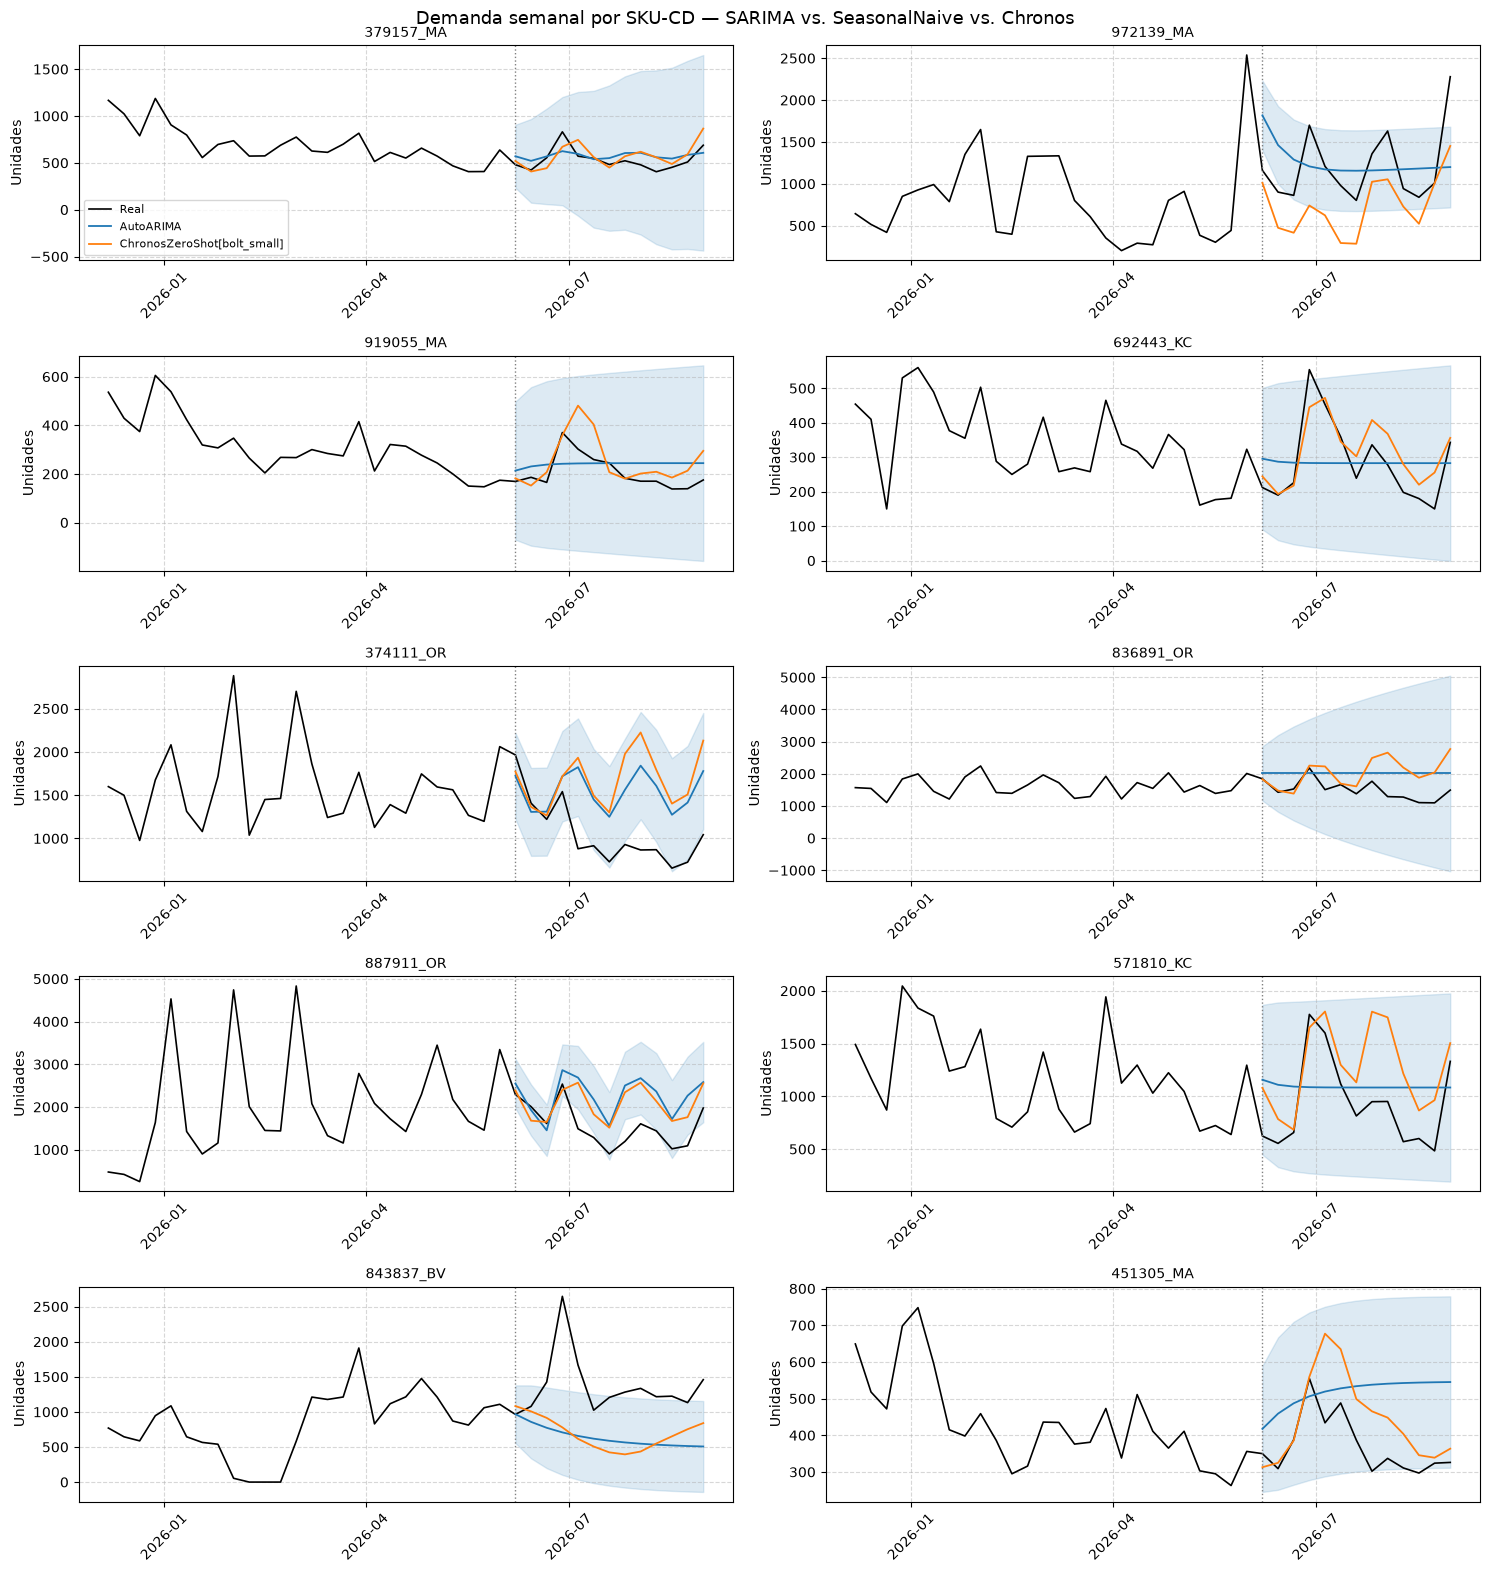

In [124]:
series_muestra = pd.Series(test_data.item_ids).sample(10, random_state=42).values

graficar_comparacion(
    predictor, train_data, test_data,
    item_ids=series_muestra,
    historia=prediction_length * 2,
    modelo_intervalo="AutoARIMA",
    titulo="Demanda semanal por SKU-CD — SARIMA vs. SeasonalNaive vs. Chronos",
)

### Conclusiones

ya nos dimos cuenta que zeroshot es mejor que sarima en todas las metricas y en el grafico se ve que va un poco como se comportan los datos reales en los trimestres cosa que pues el sarima no ahcia para nada asi que confirmamos que chronos es mejor y que usaremos ese para el modelo

## Punto 4

**Uso de los modelos: pronóstico semanal y cierre trimestral**  
Seleccionen el modelo o la combinación ganadora y reentrénenla con toda la historia disponible. Generen un **pronóstico semanal** desde la semana siguiente al último dato hasta el **cierre del cuarto trimestre de 2026** (horizonte multipaso). Entreguen:
   - Una tabla de predicciones semanales por SKU × CD, idealmente con intervalos de predicción.
   - El cierre esperado de **Q3 2026** (datos reales observados + semanas pronosticadas) y el total de **Q4 2026**, por SKU y para el total del segmento.
   - Gráficos del horizonte de pronóstico (al menos el total y algunos SKUs representativos).
   - La mejora esperada en el error trimestral frente al método actual (media móvil) y una breve guía para reproducir el proceso cada semana.

**NOTA:** NO olviden generar muchos gráficos para entender mejor los datos a los que se enfrentan

### Mejora frente al modelo base (SARIMA)

aca vamos a ver como cambia el error trimestrar de chronos y el de sarima para ver si en realidad si es mejor chronos

In [125]:
# Modelo escogido en el punto 3 (Chronos zero-shot) y su pronóstico para las 13 semanas de prueba
modelo_ganador = [m for m in predictor.model_names() if "Chronos" in m][0]
pred_ganador = predictor.predict(train_data, model=modelo_ganador)["mean"].clip(lower=0)

# Modelo base del punto 2 (SARIMA) para el mismo trimestre de prueba
pred_sarima = predictor.predict(train_data, model="AutoARIMA")["mean"].clip(lower=0)

# Unidades reales de las 13 semanas de prueba
real = test_data.slice_by_timestep(-prediction_length, None)["target"]

# Total del trimestre de prueba por serie SKU-CD: real vs. cada pronóstico
trimestre = pd.DataFrame({
    "real": real.groupby(level="item_id").sum(),
    "modelo": pred_ganador.groupby(level="item_id").sum(),
    "sarima": pred_sarima.groupby(level="item_id").sum(),
})
trimestre["SKU_NBR"] = trimestre.index.str.split("_").str[0]

# Error trimestral (WAPE): suma de errores absolutos sobre el total real, en %
def wape(real, pred):
    return 100 * (real - pred).abs().sum() / real.sum()

por_sku_trim = trimestre.groupby("SKU_NBR")[["real", "modelo", "sarima"]].sum()
total_trim = trimestre[["real", "modelo", "sarima"]].sum().to_frame().T

niveles = {"SKU-CD": trimestre, "SKU": por_sku_trim, "Total segmento": total_trim}
mejora = pd.DataFrame({
    "sarima": [wape(t["real"], t["sarima"]) for t in niveles.values()],
    "modelo": [wape(t["real"], t["modelo"]) for t in niveles.values()],
}, index=niveles.keys()).round(1)
mejora["mejora_vs_sarima"] = (mejora["sarima"] - mejora["modelo"]).round(1)

print(f"Modelo ganador: {modelo_ganador}")
print("Error trimestral (WAPE, %) en el trimestre de prueba:")
mejora

Loading weights: 100%|██████████| 143/143 [00:00<00:00, 20480.28it/s]


Modelo ganador: ChronosZeroShot[bolt_small]
Error trimestral (WAPE, %) en el trimestre de prueba:


,sarima,modelo,mejora_vs_sarima
SKU-CD,28.1,20.7,7.4
SKU,24.4,17.8,6.6
Total segmento,20.1,13.6,6.5


### Pronóstico con toda la historia

ahora armamos los datos con todas las series y a calcular esas nuevas semanas

In [126]:
# Panel con las 363 series SKU-CD (incluye las series cortas), cada una desde su primer dato
panel = semanal.copy()
panel["item_id"] = panel["SKU_NBR"].astype(str) + "_" + panel["DC_ID"].astype(str)
panel = (panel.set_index("ORDER_DATE")
         .groupby("item_id")["ITEMS_QTY"]
         .apply(lambda s: s.asfreq("W-SUN", fill_value=0))
         .reset_index()
         .rename(columns={"ORDER_DATE": "timestamp", "ITEMS_QTY": "target"}))

historia = TimeSeriesDataFrame.from_data_frame(panel, id_column="item_id", timestamp_column="timestamp")

# Semanas a pronosticar: desde la semana siguiente al último dato hasta la última semana de 2026
ultima_semana = panel["timestamp"].max()
horizonte = len(pd.date_range(ultima_semana, "2026-12-31", freq="W-SUN")) - 1

print(f"Series: {historia.num_items}")
print(f"Último dato: {ultima_semana.date()}  |  Semanas a pronosticar: {horizonte}")

Series: 363
Último dato: 2026-08-30  |  Semanas a pronosticar: 17


como ya sabemos que tnemos que predecir esas 17 semanas que faltan lo hacemos pues ocn zero shot y con esos datos

In [127]:
# Reentrenar el modelo ganador con toda la historia y pronosticar hasta el cierre de Q4 2026
predictor_final = TimeSeriesPredictor(
    prediction_length=horizonte,
    target="target",
    eval_metric="MASE",
    path="modelos/final",
)

predictor_final.fit(
    historia,
    hyperparameters={
        "Chronos": {"model_path": "bolt_small", "ag_args": {"name_suffix": "ZeroShot"}},   # modelo ganador del punto 3
    },
    enable_ensemble=False,
)

pronostico = predictor_final.predict(historia).clip(lower=0)   # no puede haber unidades negativas

Beginning AutoGluon training...
AutoGluon will save models to '/Users/teo/Documents/Parcial-Forecasting/modelos/final'
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.12.14
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 25.6.0: Fri Jul 31 19:16:20 PDT 2026; root:xnu-12377.161.14~5/RELEASE_ARM64_T8142
CPU Count:          10
Pytorch Version:    2.10.0
CUDA Version:       CUDA is not available
GPU Count:          WARNING: Exception was raised when calculating GPU count (AssertionError)
Memory Avail:       5.86 GB / 24.00 GB (24.4%)
Disk Space Avail:   74.60 GB / 460.38 GB (16.2%)

Fitting with arguments:
{'enable_ensemble': False,
 'eval_metric': MASE,
 'hyperparameters': {'Chronos': {'ag_args': {'name_suffix': 'ZeroShot'},
                                 'model_path': 'bolt_small'}},
 'known_covariates_names': [],
 'num_val_windows': 1,
 'prediction_length': 17,
 'quantile_levels': [0.1, 

ahora vamos a ver la tabla con lo que va a pedir cada producto en cada bodega cada semana, con un minimo y un maximo

In [128]:
# Tabla de predicciones semanales por SKU-CD con intervalo de predicción del 80%
tabla_pronostico = pronostico[["mean", "0.1", "0.9"]].reset_index()
tabla_pronostico[["SKU_NBR", "DC_ID"]] = tabla_pronostico["item_id"].str.split("_", expand=True)
tabla_pronostico = (tabla_pronostico
                    .rename(columns={"timestamp": "semana", "mean": "pronostico",
                                     "0.1": "limite_inferior", "0.9": "limite_superior"})
                    [["SKU_NBR", "DC_ID", "semana", "pronostico", "limite_inferior", "limite_superior"]]
                    .round(0))

tabla_pronostico

,SKU_NBR,DC_ID,semana,pronostico,limite_inferior,limite_superior
0,100032,KC,2026-09-06,1038.0,686.0,1520.0
1,100032,KC,2026-09-13,895.0,473.0,1389.0
2,100032,KC,2026-09-20,947.0,466.0,1463.0
3,100032,KC,2026-09-27,1365.0,818.0,1982.0
4,100032,KC,2026-10-04,1687.0,1020.0,2425.0
...,...,...,...,...,...,...
6166,998700,OR,2026-11-29,719.0,486.0,1026.0
6167,998700,OR,2026-12-06,637.0,438.0,961.0
6168,998700,OR,2026-12-13,486.0,291.0,793.0
6169,998700,OR,2026-12-20,472.0,280.0,772.0


### Cierre de Q3 2026 y total de Q4 2026

ahora vamos a ver como cerraria el Q3 juntando lo real con lo pronosticado y cuanto daria el Q4, comparado con el 2025

In [129]:
# Unir datos reales y pronosticados, y asignar cada semana a su trimestre (según el domingo que la identifica)
reales = panel.rename(columns={"target": "unidades"}).assign(tipo="Real")
pronosticados = pronostico["mean"].rename("unidades").reset_index().assign(tipo="Pronóstico")
combinado = pd.concat([reales, pronosticados], ignore_index=True)
combinado["SKU_NBR"] = combinado["item_id"].str.split("_").str[0]
combinado["trimestre"] = combinado["timestamp"].dt.to_period("Q").astype(str)

def suma(trimestre, tipo=None):
    filtro = combinado["trimestre"] == trimestre
    if tipo:
        filtro &= combinado["tipo"] == tipo
    return combinado[filtro].groupby("SKU_NBR")["unidades"].sum()

# Cierre por SKU: Q3 2026 = semanas reales + semanas pronosticadas; Q4 2026 = todo pronosticado
cierre = pd.DataFrame({
    "Q3 2025 real": suma("2025Q3"),
    "Q3 2026 real": suma("2026Q3", "Real"),
    "Q3 2026 pronosticado": suma("2026Q3", "Pronóstico"),
    "Q3 2026 cierre esperado": suma("2026Q3"),
    "Q4 2025 real": suma("2025Q4"),
    "Q4 2026 pronóstico": suma("2026Q4"),
}).fillna(0).round(0)
cierre.loc["Total segmento"] = cierre.sum()

# Variación frente al mismo trimestre del año anterior
cierre["variacion_Q3_%"] = (100 * (cierre["Q3 2026 cierre esperado"] / cierre["Q3 2025 real"] - 1)).round(1)
cierre["variacion_Q4_%"] = (100 * (cierre["Q4 2026 pronóstico"] / cierre["Q4 2025 real"] - 1)).round(1)

cierre.loc[["Total segmento"]]

,Q3 2025 real,Q3 2026 real,Q3 2026 pronosticado,Q3 2026 cierre esperado,Q4 2025 real,Q4 2026 pronóstico,variacion_Q3_%,variacion_Q4_%
SKU_NBR,,,,,,,,
Total segmento,5286115.0,2850090.0,1385455.0,4235545.0,5650883.0,4596022.0,-19.9,-18.7


ahora es ver lo mismo epro tipo por producto

In [130]:
# Cierre por SKU, de mayor a menor volumen en Q4 2026
cierre.drop("Total segmento").sort_values("Q4 2026 pronóstico", ascending=False)

,Q3 2025 real,Q3 2026 real,Q3 2026 pronosticado,Q3 2026 cierre esperado,Q4 2025 real,Q4 2026 pronóstico,variacion_Q3_%,variacion_Q4_%
SKU_NBR,,,,,,,,
910693,493336.0,329379.0,157437.0,486816.0,513316.0,529631.0,-1.3,3.2
740537,124435.0,108265.0,42907.0,151172.0,146835.0,154992.0,21.5,5.6
692270,145088.0,93250.0,46339.0,139589.0,186415.0,153153.0,-3.8,-17.8
571810,218592.0,102242.0,45794.0,148036.0,195792.0,152044.0,-32.3,-22.3
888491,164943.0,100836.0,43867.0,144703.0,147314.0,137004.0,-12.3,-7.0
...,...,...,...,...,...,...,...,...
390195,10131.0,1846.0,804.0,2650.0,8270.0,2689.0,-73.8,-67.5
329818,3467.0,1309.0,577.0,1886.0,3767.0,2110.0,-45.6,-44.0
478059,2847.0,1477.0,337.0,1814.0,1885.0,1145.0,-36.3,-39.3


### Gráficos del horizonte de pronóstico

ahora es ver cel grafico todal del pronostico

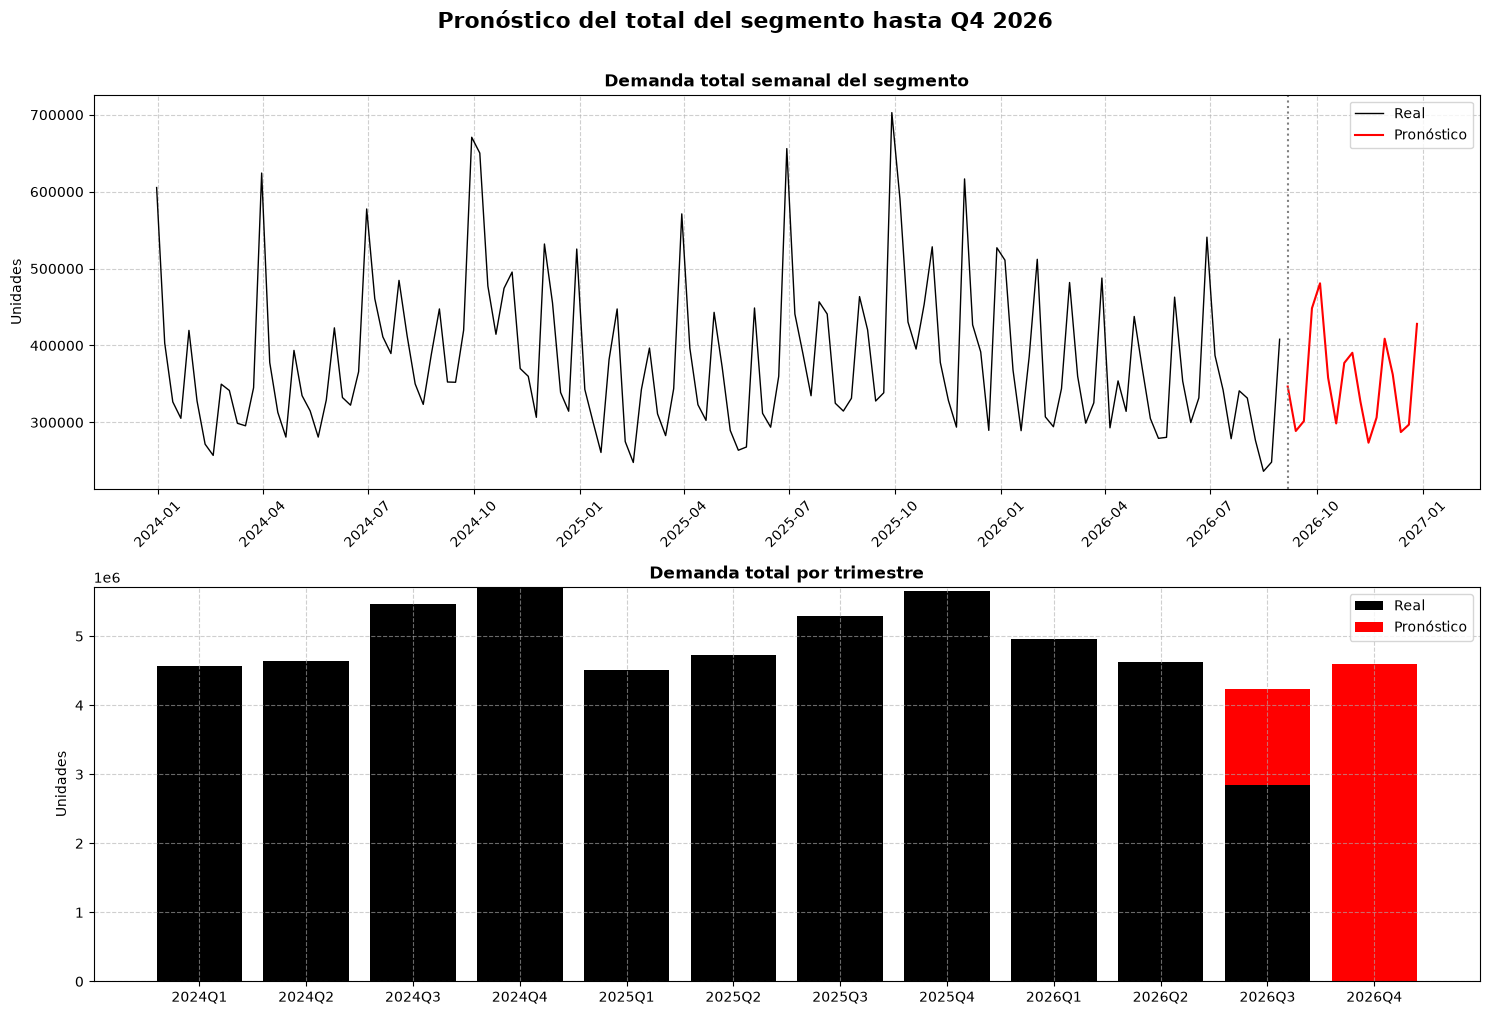

In [131]:
# Total del segmento por semana: historia real y pronóstico
total_real = panel.groupby("timestamp")["target"].sum()
total_pron = pronostico["mean"].groupby(level="timestamp").sum()

# Total por trimestre, separando lo real de lo pronosticado
por_trimestre = combinado.pivot_table(index="trimestre", columns="tipo", values="unidades", aggfunc="sum", fill_value=0)
por_trimestre = por_trimestre.loc[por_trimestre.index >= "2024Q1"]

fig, axes = plt.subplots(2, 1, figsize=(15, 10))

axes[0].plot(total_real, color="black", linewidth=1, label="Real")
axes[0].plot(total_pron, color="red", linewidth=1.5, label="Pronóstico")
axes[0].axvline(total_pron.index[0], color="gray", linestyle=":")
axes[0].set_title("Demanda total semanal del segmento", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Unidades")
axes[0].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))   # un tick por trimestre
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend()

axes[1].bar(por_trimestre.index, por_trimestre["Real"], color="black", label="Real")
axes[1].bar(por_trimestre.index, por_trimestre["Pronóstico"], bottom=por_trimestre["Real"], color="red", label="Pronóstico")
axes[1].set_title("Demanda total por trimestre", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Unidades")
axes[1].legend()

# Ajustes estéticos
for ax in axes:
    ax.grid(True, linestyle="--", alpha=0.6)

plt.suptitle("Pronóstico del total del segmento hasta Q4 2026", fontsize=16, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

vamos a ver como se pronostico ese producto mas grande de cada cd, y se añadieron skus representativos como un producto nuevo y uno descontinuado para ver como se comportaban

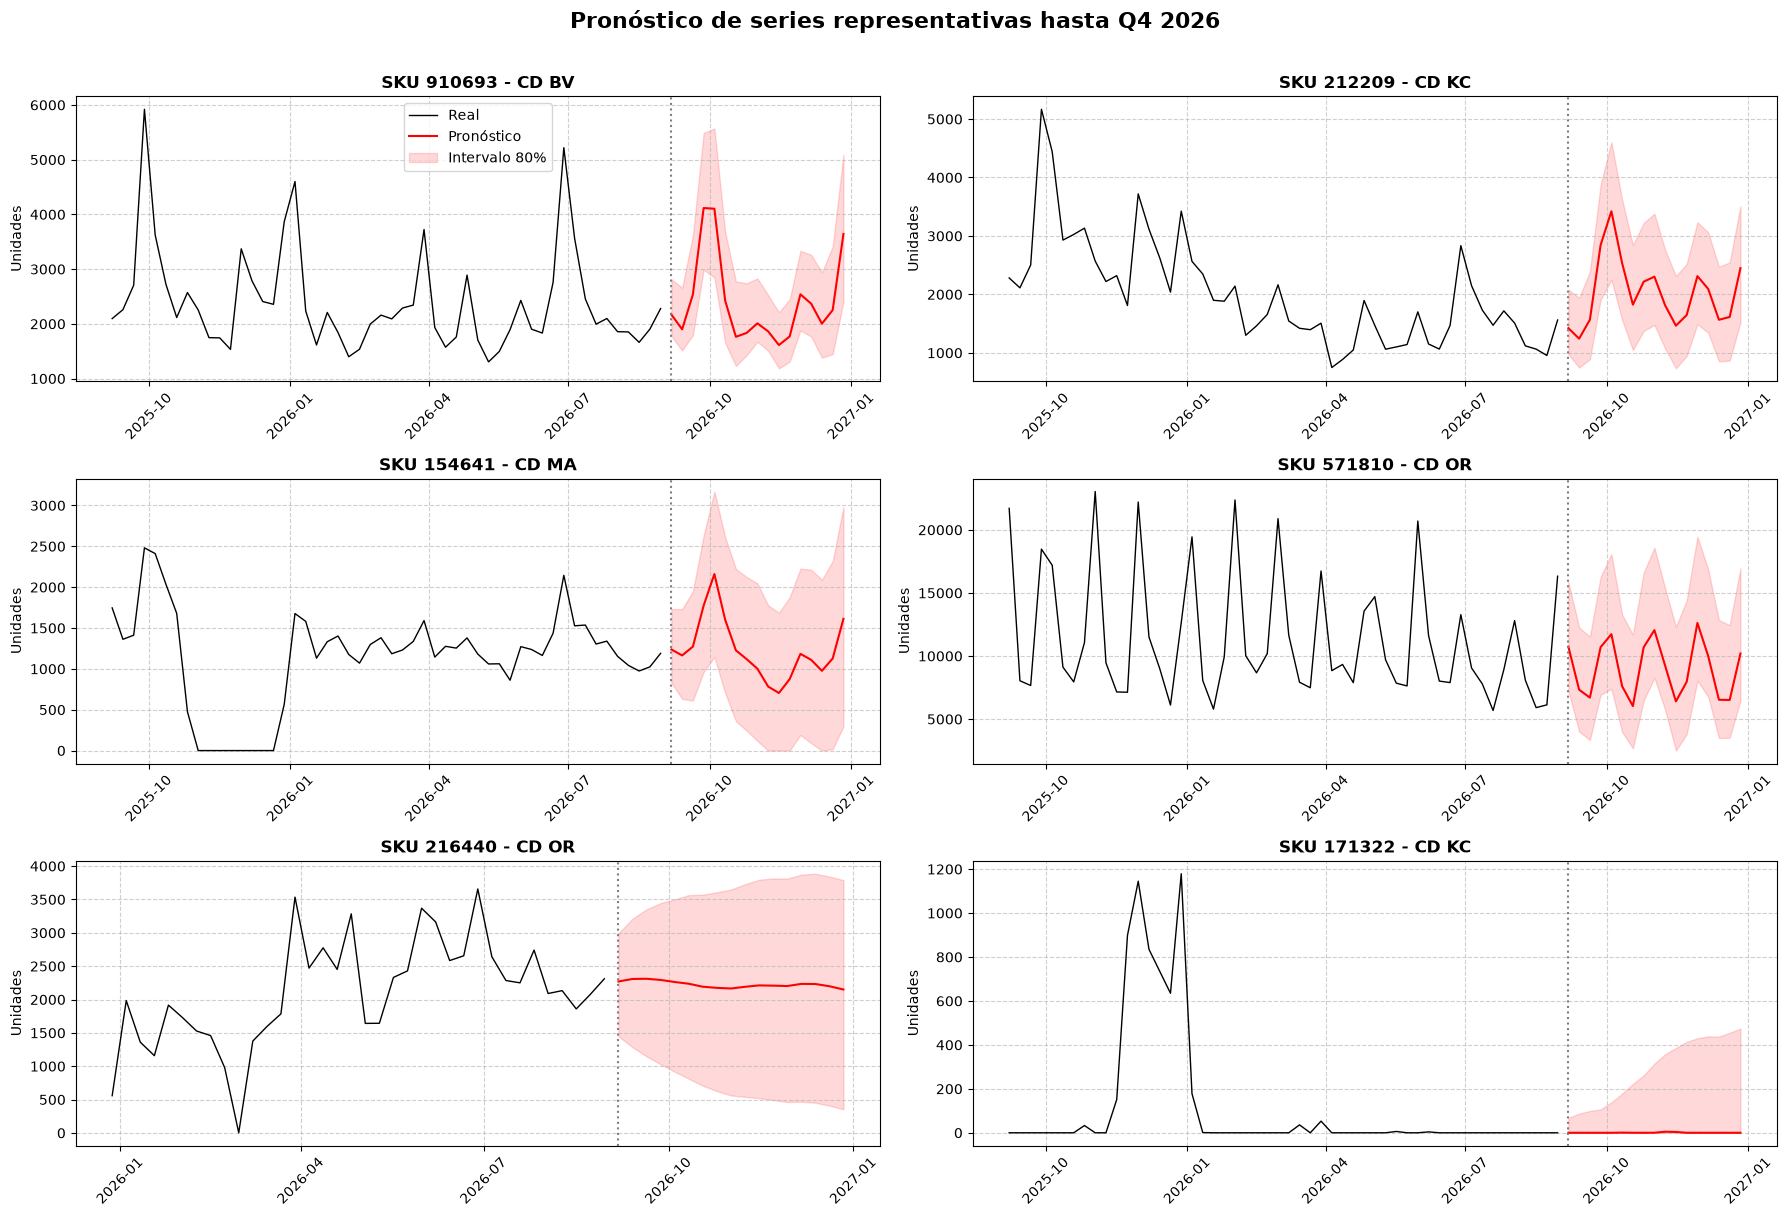

In [132]:
# Series representativas: la de mayor volumen de cada CD (sin repetir SKU), una serie nueva y una posiblemente descontinuada
volumen = panel.groupby("item_id")["target"].sum().sort_values(ascending=False)
representativas = []
for dc in ["BV", "KC", "MA", "OR"]:
    skus_elegidos = [r.split("_")[0] for r in representativas]
    candidatas = [i for i in volumen.index if i.endswith("_" + dc) and i.split("_")[0] not in skus_elegidos]
    representativas.append(candidatas[0])
representativas += ["216440_OR", "171322_KC"]

fig, axes = plt.subplots(3, 2, figsize=(18, 12))

for ax, item in zip(axes.flat, representativas):
    real_item = historia.loc[item]["target"].iloc[-52:]   # último año de historia
    pron_item = pronostico.loc[item]
    ax.plot(real_item, color="black", linewidth=1, label="Real")
    ax.plot(pron_item["mean"], color="red", linewidth=1.5, label="Pronóstico")
    ax.fill_between(pron_item.index, pron_item["0.1"], pron_item["0.9"], color="red", alpha=0.15, label="Intervalo 80%")
    ax.axvline(pron_item.index[0], color="gray", linestyle=":")
    ax.set_title(f"SKU {item.split('_')[0]} - CD {item.split('_')[1]}", fontsize=12, fontweight="bold")
    ax.set_ylabel("Unidades")

# Ajustes estéticos
for ax in axes.flat:
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))   # un tick por trimestre
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.tick_params(axis="x", rotation=45)
axes.flat[0].legend()

plt.suptitle("Pronóstico de series representativas hasta Q4 2026", fontsize=16, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

### Conclusiones

En si ya vimos que zero shot de Chronos es mejor que sarima entonces pronosticamos las 363 series que teniamos y las nuevas para esos SKUs significativos, y para el Q3 y el Q4 de 2026 se espera que se pida un poco menos que en el 2025 porque la demanda ya venia bajando, y pues vimos que en el grafico del pronostico sigue los picos y cuano termina los trimestres pero los termina un poco mas abajo y tambien vimos que en los rpoductos representativos el nuevo es muy plano porque no tiene casi info y el que se descontinua termina en cero que es lo que deberia pasar

# Mejor Modelo

## Autogluon

Va a entrenar naive, seasonal naive, el AutoARIMA (SARIMA) y Chronos ZeroShot que ya calculamos antes y un Chronos FineTuned

In [133]:
# 1. Guardar el predictor del punto 3 con otro nombre ANTES de crear el nuevo
predictor_p3 = predictor

# 2. Solo los modelos que faltan
predictor_nuevos = TimeSeriesPredictor(
    prediction_length=prediction_length,
    target="target",
    eval_metric="MASE",
    eval_metric_seasonal_period=13,
)

predictor_nuevos.fit(
    train_data,
    hyperparameters={
        "Naive": {},
        "SeasonalNaive": {"season_length": 13},
        "Chronos": {"model_path": "bolt_small", "fine_tune": True, "ag_args": {"name_suffix": "FineTuned"}},
    },
    enable_ensemble=False,
)

# 3. Pronósticos de los dos predictores en formato largo
preds = []
for pred_obj in [predictor_p3, predictor_nuevos]:
    for modelo in pred_obj.model_names():
        p = pred_obj.predict(train_data, model=modelo)["mean"].reset_index()
        p.columns = ["unique_id", "ds", "yhat"]
        p["modelo"] = modelo
        preds.append(p)

print(pd.concat(preds)["modelo"].value_counts())   # deben salir los 5 modelos con el mismo número de filas

Beginning AutoGluon training...
AutoGluon will save models to '/Users/teo/Documents/Parcial-Forecasting/AutogluonModels/ag-20261019_123910'
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.12.14
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 25.6.0: Fri Jul 31 19:16:20 PDT 2026; root:xnu-12377.161.14~5/RELEASE_ARM64_T8142
CPU Count:          10
Pytorch Version:    2.10.0
CUDA Version:       CUDA is not available
GPU Count:          WARNING: Exception was raised when calculating GPU count (AssertionError)
Memory Avail:       5.56 GB / 24.00 GB (23.1%)
Disk Space Avail:   74.60 GB / 460.38 GB (16.2%)

Fitting with arguments:
{'enable_ensemble': False,
 'eval_metric': MASE,
 'eval_metric_seasonal_period': 13,
 'hyperparameters': {'Chronos': {'ag_args': {'name_suffix': 'FineTuned'},
                                 'fine_tune': True,
                                 'model_path': 'bolt_small'

modelo
AutoARIMA                       4537
ChronosZeroShot[bolt_small]     4537
Naive                           4537
SeasonalNaive                   4537
ChronosFineTuned[bolt_small]    4537
Name: count, dtype: int64


## Nixtla (N-Hits)

In [134]:
train_nx = (train_data.reset_index()
            .rename(columns={"item_id": "unique_id", "timestamp": "ds", "target": "y"}))

In [135]:
nf = NeuralForecast(
    models=[NHITS(
        h=prediction_length,          # 26 semanas
        input_size=52,                # mira el último año para pronosticar
        loss=MAE(),
        scaler_type="robust",
        max_steps=500,
        start_padding_enabled=True,   # por si alguna serie es corta
        random_seed=42,
    )],
    freq="W-SUN",
)
nf.fit(df=train_nx)

p = nf.predict()
if "unique_id" not in p.columns:      # según la versión viene como índice o como columna
    p = p.reset_index()
p = p.rename(columns={"NHITS": "yhat"})[["unique_id", "ds", "yhat"]]
p["modelo"] = "NHITS"
preds.append(p)

Seed set to 42
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


┏━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name                ┃ Type          ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ loss                │ MAE           │      0 │ train │     0 │
│ 1 │ hist_cat_embeddings │ ModuleList    │      0 │ train │     0 │
│ 2 │ futr_cat_embeddings │ ModuleList    │      0 │ train │     0 │
│ 3 │ stat_cat_embeddings │ ModuleList    │      0 │ train │     0 │
│ 4 │ padder_train        │ ConstantPad1d │      0 │ train │     0 │
│ 5 │ scaler              │ TemporalNorm  │      0 │ train │     0 │
│ 6 │ blocks              │ ModuleList    │  2.5 M │ train │     0 │
└───┴─────────────────────┴───────────────┴────────┴───────┴───────┘

Trainable params: 2.5 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 2.5 M                                                                                                
Total estimated model params size (MB): 10.040                                                                     
Modules in train mode: 37                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

/Users/teo/.venv/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install "ipywidgets" for Jupyter 
support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Users/teo/.venv/lib/python3.12/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, 
LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

`Trainer.fit` stopped: `max_steps=500` reached.


GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


/Users/teo/.venv/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install "ipywidgets" for Jupyter 
support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Users/teo/.venv/lib/python3.12/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


## Prophet

In [136]:
filas = []
for uid, g in train_nx.groupby("unique_id"):
    m = Prophet(yearly_seasonality=False, weekly_seasonality=False, daily_seasonality=False)
    m.add_seasonality(name="trimestral", period=365.25 / 4, fourier_order=5)   # 13 semanas, en días
    m.fit(g[["ds", "y"]])

    futuro = m.make_future_dataframe(periods=prediction_length, freq="W-SUN", include_history=False)
    f = m.predict(futuro)[["ds", "yhat"]]
    f["unique_id"] = uid
    filas.append(f)

p = pd.concat(filas, ignore_index=True)
p["modelo"] = "Prophet"
preds.append(p)

## Comparación Modelos Globales

In [137]:
pred = pd.concat(preds, ignore_index=True)

real = (test_data.reset_index()
        .rename(columns={"item_id": "unique_id", "timestamp": "ds", "target": "y"}))
comp = pred.merge(real[["unique_id", "ds", "y"]], on=["unique_id", "ds"], how="left")
assert comp["y"].notna().all(), "Hay pronósticos sin valor real: revisa fechas"

# Escala del MASE: error del naive estacional (13 semanas) dentro del train de cada serie
escala = (train_nx.groupby("unique_id")["y"]
          .apply(lambda s: s.diff(13).abs().mean())
          .rename("escala").reset_index())
comp = comp.merge(escala, on="unique_id")
comp["error"] = comp["y"] - comp["yhat"]

def metricas_globales(g):
    mase_serie = (g["error"].abs().groupby(g["unique_id"]).mean()
                  / g.groupby("unique_id")["escala"].first()).replace(np.inf, np.nan)
    return pd.Series({
        "WAPE": g["error"].abs().sum() / g["y"].abs().sum(),        # pesa el volumen
        "MASE": mase_serie.mean(),                                  # cada serie pesa igual
        "MAE": g["error"].abs().mean(),
        "RMSE": np.sqrt((g["error"] ** 2).mean()),
    })

tabla = comp.groupby("modelo").apply(metricas_globales).sort_values("WAPE")
tabla.round(3)

/var/folders/5d/bx9s1w5n2rxbh0kx7yyr1qwr0000gn/T/ipykernel_83595/2669654515.py:25: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tabla = comp.groupby("modelo").apply(metricas_globales).sort_values("WAPE")


,WAPE,MASE,MAE,RMSE
modelo,,,,
NHITS,0.266,0.521,240.288,610.945
ChronosFineTuned[bolt_small],0.267,0.546,241.235,583.941
ChronosZeroShot[bolt_small],0.289,0.615,261.629,582.573
Prophet,0.344,0.731,311.082,650.064
AutoARIMA,0.390,0.732,352.520,1084.042
Naive,0.536,0.940,484.081,1407.810
SeasonalNaive,0.536,0.940,484.081,1407.810


In [138]:
wape_por_serie = (comp.groupby(["modelo", "unique_id"])
                  .apply(lambda g: g["error"].abs().sum() / g["y"].abs().sum()
                         if g["y"].abs().sum() > 0 else np.nan)
                  .unstack(0))
wape_por_serie.dropna(how="all").idxmin(axis=1).value_counts()

/var/folders/5d/bx9s1w5n2rxbh0kx7yyr1qwr0000gn/T/ipykernel_83595/1086597516.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g["error"].abs().sum() / g["y"].abs().sum()


NHITS                           137
ChronosFineTuned[bolt_small]     97
AutoARIMA                        37
Prophet                          33
ChronosZeroShot[bolt_small]      28
Naive                            17
Name: count, dtype: int64

## Comparación Modelos Individuales

In [139]:
metricas = ["WAPE", "MASE", "MAE", "RMSE"]

# 1. Métricas de cada modelo en cada serie (mismas definiciones que la tabla general)
comp["abs_err"] = comp["error"].abs()
comp["sq_err"] = comp["error"] ** 2
comp["abs_y"] = comp["y"].abs()

metricas_serie = (comp.groupby(["unique_id", "modelo"])
                  .agg(sum_abs_err=("abs_err", "sum"),
                       sum_abs_y=("abs_y", "sum"),
                       MAE=("abs_err", "mean"),
                       MSE=("sq_err", "mean"),
                       escala=("escala", "first"))
                  .reset_index())

metricas_serie["WAPE"] = metricas_serie["sum_abs_err"] / metricas_serie["sum_abs_y"].replace(0, np.nan)
metricas_serie["MASE"] = metricas_serie["MAE"] / metricas_serie["escala"].replace(0, np.nan)
metricas_serie["RMSE"] = np.sqrt(metricas_serie["MSE"])

# 2. Ranking por WAPE dentro de cada serie (MAE como desempate o si el WAPE no se puede calcular)
metricas_serie = metricas_serie.sort_values(["unique_id", "WAPE", "MAE"], na_position="last")
metricas_serie["puesto"] = metricas_serie.groupby("unique_id").cumcount() + 1

mejor_serie = metricas_serie[metricas_serie["puesto"] == 1].set_index("unique_id")
segundo_serie = metricas_serie[metricas_serie["puesto"] == 2].set_index("unique_id")

# 3. Tabla: mejor modelo y sus métricas, segundo modelo y sus métricas
tabla_series = pd.concat(
    {"Mejor": mejor_serie[["modelo"] + metricas],
     "Segundo": segundo_serie[["modelo"] + metricas]},
    axis=1,
)

# 4. Una tabla por cada modelo ganador
tablas_por_modelo = {
    modelo: g.sort_values(("Mejor", "WAPE"))
    for modelo, g in tabla_series.groupby(("Mejor", "modelo"))
}

for modelo, t in tablas_por_modelo.items():
    print(f"\n=== Mejor modelo: {modelo} ({len(t)} series) ===")
    with pd.option_context("display.max_rows", None):
        display(t.round(3))


=== Mejor modelo: AutoARIMA (37 series) ===


Mejor                                    \
              modelo   WAPE   MASE       MAE      RMSE   
unique_id                                                
715123_OR  AutoARIMA  0.141  0.477    97.195   128.169   
127200_OR  AutoARIMA  0.144  0.375   117.055   147.845   
531343_OR  AutoARIMA  0.149  0.476    66.842    87.383   
448404_OR  AutoARIMA  0.161  0.182    67.176    93.982   
289061_MA  AutoARIMA  0.166  0.382   126.222   165.521   
232907_MA  AutoARIMA  0.178  0.364    64.409    85.006   
964606_OR  AutoARIMA  0.191  0.210    45.088    55.495   
454376_MA  AutoARIMA  0.193  0.368   217.110   302.137   
705527_KC  AutoARIMA  0.193  0.093    67.570   110.910   
482019_OR  AutoARIMA  0.197  0.287    58.274    70.658   
277898_OR  AutoARIMA  0.201  0.344    55.123    60.407   
289061_OR  AutoARIMA  0.210  0.392   172.305   195.955   
692443_OR  AutoARIMA  0.228  0.506   129.058   147.350   
964606_KC  AutoARIMA  0.229  0.185    49.955    67.831   
278559_OR  AutoARIMA  0.234  0.403   115.083   141.967   
949628_OR  AutoARIMA  0.248  0.974   219.462   239.780   
234977_OR  AutoARIMA  0.256  0.553   153.852   173.126   
843837_MA  AutoARIMA  0.257  0.424   496.825   637.445   
219626_MA  AutoARIMA  0.277  0.427    70.174    79.290   
365244_OR  AutoARIMA  0.285  0.904   343.702   392.354   
998700_OR  AutoARIMA  0.287  1.147   187.629   206.029   
808702_OR  AutoARIMA  0.296  0.832   372.342   422.571   
956360_OR  AutoARIMA  0.302  0.998   631.446   744.132   
390195_OR  AutoARIMA  0.304  0.417    70.884    81.360   
452206_OR  AutoARIMA  0.327  1.118   358.727   394.653   
705527_OR  AutoARIMA  0.334  0.213   153.544   164.864   
214174_OR  AutoARIMA  0.345  0.534    95.985   114.832   
264733_OR  AutoARIMA  0.353  1.396   890.788  1036.534   
219626_KC  AutoARIMA  0.359  0.381    69.506    76.855   
191238_OR  AutoARIMA  0.436  1.251   217.816   242.313   
140574_OR  AutoARIMA  0.437  1.605   254.134   279.172   
882775_OR  AutoARIMA  0.485  0.736   244.972   282.658   
374111_OR  AutoARIMA  0.508  1.455   537.833   610.279   
279013_OR  AutoARIMA  0.510  0.942   615.537   672.453   
864739_OR  AutoARIMA  0.513  0.733   173.070   197.911   
336263_OR  AutoARIMA  0.565  1.337  1494.036  1970.410   
103571_OR  AutoARIMA  0.643  1.758   412.216   454.735   

                                Segundo                                    
                                 modelo   WAPE   MASE       MAE      RMSE  
unique_id                                                                  
715123_OR                         NHITS  0.155  0.523   106.753   140.342  
127200_OR                         NHITS  0.166  0.434   135.430   167.697  
531343_OR                         Naive  0.189  0.604    84.923   103.222  
448404_OR  ChronosFineTuned[bolt_small]  0.168  0.190    70.341    78.945  
289061_MA                       Prophet  0.207  0.475   156.617   213.731  
232907_MA  ChronosFineTuned[bolt_small]  0.186  0.379    67.025    85.239  
964606_OR                         Naive  0.215  0.235    50.615    61.893  
454376_MA                         NHITS  0.195  0.372   219.419   284.267  
705527_KC                         Naive  0.207  0.100    72.462   105.305  
482019_OR                         NHITS  0.209  0.304    61.752    65.301  
277898_OR                         Naive  0.206  0.354    56.769    63.295  
289061_OR                       Prophet  0.217  0.403   177.452   211.697  
692443_OR                         Naive  0.257  0.570   145.231   169.466  
964606_KC   ChronosZeroShot[bolt_small]  0.273  0.220    59.514    68.467  
278559_OR                         Naive  0.335  0.577   164.538   213.811  
949628_OR                         NHITS  0.257  1.010   227.421   259.628  
234977_OR                       Prophet  0.314  0.678   188.696   219.953  
843837_MA  ChronosFineTuned[bolt_small]  0.299  0.495   579.735   713.257  
219626_MA  ChronosFineTuned[bolt_small]  0.293  0.452    74.238    89.741  
365244_OR   ChronosZer


=== Mejor modelo: ChronosFineTuned[bolt_small] (97 series) ===


Mejor                                    \
                                 modelo   WAPE   MASE       MAE      RMSE   
unique_id                                                                   
448404_KC  ChronosFineTuned[bolt_small]  0.064  0.121    77.431   133.011   
214395_MA  ChronosFineTuned[bolt_small]  0.075  0.203    29.681    39.799   
343885_MA  ChronosFineTuned[bolt_small]  0.078  0.207    29.795    39.167   
214395_KC  ChronosFineTuned[bolt_small]  0.079  0.145    26.013    39.445   
366732_KC  ChronosFineTuned[bolt_small]  0.080  0.087    16.797    21.079   
234585_MA  ChronosFineTuned[bolt_small]  0.081  0.196   124.853   167.959   
715123_MA  ChronosFineTuned[bolt_small]  0.085  0.248    49.951    70.745   
193588_KC  ChronosFineTuned[bolt_small]  0.089  0.206    96.113   137.849   
282267_MA  ChronosFineTuned[bolt_small]  0.094  0.288    81.965   114.420   
124886_KC  ChronosFineTuned[bolt_small]  0.095  0.172    35.879    44.941   
130344_KC  ChronosFineTuned[bolt_small]  0.095  0.195   128.346   173.660   
879536_MA  ChronosFineTuned[bolt_small]  0.099  0.208    49.741    64.033   
230268_MA  ChronosFineTuned[bolt_small]  0.100  0.218    35.438    41.599   
275530_MA  ChronosFineTuned[bolt_small]  0.102  0.131    32.145    41.181   
235332_KC  ChronosFineTuned[bolt_small]  0.105  0.316    66.083    84.971   
713639_MA  ChronosFineTuned[bolt_small]  0.105  0.331    54.954    78.678   
713639_KC  ChronosFineTuned[bolt_small]  0.106  0.271    42.643    50.652   
970823_MA  ChronosFineTuned[bolt_small]  0.107  0.281    51.953    71.650   
213330_MA  ChronosFineTuned[bolt_small]  0.108  0.194   123.643   182.673   
212209_KC  ChronosFineTuned[bolt_small]  0.111  0.192   168.370   240.153   
964701_MA  ChronosFineTuned[bolt_small]  0.113  0.291    67.134    78.566   
248570_MA  ChronosFineTuned[bolt_small]  0.114  0.319    80.222   112.554   
910693_BV  ChronosFineTuned[bolt_small]  0.115  0.437   276.526   448.230   
237416_MA  ChronosFineTuned[bolt_small]  0.117  0.348    60.297    78.938   
872912_MA  ChronosFineTuned[bolt_small]  0.119  0.220    70.711    86.520   
531343_KC  ChronosFineTuned[bolt_small]  0.119  0.254    38.166    49.167   
879536_KC  ChronosFineTuned[bolt_small]  0.119  0.128    51.804    81.380   
702514_MA  ChronosFineTuned[bolt_small]  0.120  0.322    52.565    66.956   
212209_OR  ChronosFineTuned[bolt_small]  0.120  0.201    94.210   148.156   
234978_KC  ChronosFineTuned[bolt_small]  0.120  0.160   131.455   182.715   
881367_KC  ChronosFineTuned[bolt_small]  0.121  0.269    71.898    98.109   
265212_MA  ChronosFineTuned[bolt_small]  0.121  0.429    93.280   108.671   
860410_MA  ChronosFineTuned[bolt_small]  0.122  0.247    98.915   119.098   
337711_MA  ChronosFineTuned[bolt_small]  0.124  0.206    59.265    77.050   
329818_KC  ChronosFineTuned[bolt_small]  0.125  0.085    20.339    28.527   
179666_KC  ChronosFineTuned[bolt_small]  0.125  0.170    34.098    47.703   
164020_KC  ChronosFineTuned[bolt_small]  0.126  0.222    47.685    60.578   
241483_KC  ChronosFineTuned[bolt_small]  0.126  0.174    40.241    50.668   
888292_KC  ChronosFineTuned[bolt_small]  0.126  0.104    20.629    24.257   
379157_KC  ChronosFineTuned[bolt_small]  0.128  0.113    57.011    64.686   
695912_MA  ChronosFineTuned[bolt_small]  0.128  0.155    34.654    58.120   
371948_MA  ChronosFineTuned[bolt_small]  0.130  0.199    77.015   101.663   
122340_OR  ChronosFineTuned[bolt_small]  0.130  0.211    46.702    63.373   
309433_MA  ChronosFineTuned[bolt_small]  0.130  0.312   116.061   171.228   
230268_KC  ChronosFineTuned[bolt_small]  0.132  0.194    40.978    48.078   
715123_KC  ChronosFineTuned[bolt_small]  0.133  0.304    73.915   102.600   
933844_MA  ChronosFineTuned[bolt_small]  0.135  0.325    97.926   140.771   
343885_KC  ChronosFineTuned[bolt_small]  0.136  0.169    40.813    53.739   
447703_BV  ChronosFineTuned[bolt_small]  0.137  0.530    56.816    87.336   
933844_KC  ChronosFineTuned[bo


=== Mejor modelo: ChronosZeroShot[bolt_small] (28 series) ===


...

Mejor                                    \
          modelo   WAPE   MASE       MAE      RMSE   
unique_id                                            
991269_MA  NHITS  0.068  0.218    39.994    46.835   
972139_MA  NHITS  0.072  0.303    87.158    98.459   
322430_MA  NHITS  0.074  0.068    16.035    19.256   
212209_MA  NHITS  0.079  0.188   180.186   251.010   
193588_MA  NHITS  0.079  0.222   106.465   160.350   
448404_BV  NHITS  0.081  0.195    36.058    58.375   
365244_MA  NHITS  0.081  0.096    33.279    39.895   
179666_MA  NHITS  0.084  0.174    25.617    35.301   
451305_KC  NHITS  0.085  0.194    25.142    31.561   
482019_MA  NHITS  0.086  0.126    40.067    47.601   
126623_MA  NHITS  0.086  0.111    27.195    34.740   
836891_MA  NHITS  0.086  0.280    58.989    74.711   
317581_KC  NHITS  0.087  0.066    23.042    29.808   
882775_MA  NHITS  0.089  0.180    58.653    72.506   
881367_MA  NHITS  0.089  0.243    54.209    78.922   
451305_MA  NHITS  0.089  0.237    32.901    41.586   
457492_MA  NHITS  0.091  0.149    45.244    59.969   
956360_MA  NHITS  0.092  0.192    60.773    73.086   
416639_MA  NHITS  0.094  0.270    43.930    56.173   
373019_KC  NHITS  0.097  0.051    17.726    22.138   
237544_MA  NHITS  0.099  0.153    92.005   133.628   
571810_MA  NHITS  0.100  0.300   146.387   175.100   
154641_MA  NHITS  0.101  0.175   132.537   204.271   
336263_MA  NHITS  0.102  0.386   136.476   157.396   
371948_KC  NHITS  0.102  0.119    55.747    76.684   
130344_MA  NHITS  0.102  0.311   169.840   257.236   
213330_KC  NHITS  0.103  0.124    85.337   126.591   
100032_MA  NHITS  0.103  0.298   120.860   167.863   
692443_MA  NHITS  0.105  0.321    42.427    54.123   
379157_MA  NHITS  0.105  0.144    56.042    68.861   
317581_MA  NHITS  0.108  0.147    34.663    44.214   
740537_MA  NHITS  0.110  0.551   166.926   233.676   
970823_KC  NHITS  0.110  0.191    39.101    47.068   
122340_KC  NHITS  0.110  0.122    79.090    99.321   
949628_MA  NHITS  0.112  0.428    58.397    72.961   
122340_MA  NHITS  0.113  0.198   107.705   167.754   
485926_MA  NHITS  0.114  0.422   202.734   250.439   
234978_MA  NHITS  0.114  0.255   161.117   195.085   
448393_KC  NHITS  0.115  0.095    41.630    51.423   
154641_KC  NHITS  0.117  0.142   106.445   131.179   
927025_OR  NHITS  0.118  0.519   116.434   154.702   
122869_KC  NHITS  0.119  0.178    31.104    37.082   
482019_KC  NHITS  0.120  0.147    45.132    49.384   
239673_KC  NHITS  0.123  0.196    64.112    89.390   
951344_MA  NHITS  0.125  0.160    36.516    57.976   
550749_KC  NHITS  0.126  0.134    41.183    52.339   
717911_KC  NHITS  0.127  0.174    41.470    49.831   
702514_KC  NHITS  0.127  0.177    42.221    49.135   
206805_KC  NHITS  0.128  0.136    30.769    37.287   
448404_MA  NHITS  0.129  0.267   174.826   254.030   
278382_MA  NHITS  0.129  0.322   152.502   211.392   
459960_MA  NHITS  0.131  0.333    96.925   129.858   
237544_OR  NHITS  0.133  0.332   160.012   201.719   
371914_MA  NHITS  0.136  0.120    33.309    36.690   
309433_OR  NHITS  0.139  0.600   475.933   596.399   
448393_MA  NHITS  0.141  0.172    51.235    58.803   
302860_KC  NHITS  0.141  0.102    24.516    29.028   
124886_MA  NHITS  0.141  0.341    54.207    84.715   
350480_MA  NHITS  0.142  0.565    59.309    78.910   
695912_KC  NHITS  0.142  0.147    31.966    39.955   
692270_KC  NHITS  0.143  0.249   235.799   288.483   
130344_OR  NHITS  0.144  0.486   316.919   360.475   
520577_BV  NHITS  0.145  0.558   101.554   175.003   
365244_KC  NHITS  0.146  0.135    53.412    66.908   
458004_MA  NHITS  0.149  0.214    96.003   114.785   
302860_MA  NHITS  0.149  0.155    32.630    36.584   
268542_KC  NHITS  0.150  0.181    37.217    45.166   
278559_MA  NHITS  0.151  0.246    58.432    72.522   
888292_MA  NHITS  0.153  0.156    29.778    35.348   
547802_KC  NHITS  0.153  0.350   125.482   202.121   
710787_KC  NHITS  0.153  0.335   150.433   183.551   
239673_MA  NHIT


=== Mejor modelo: Naive (17 series) ===


Mejor                                        Segundo                \
          modelo   WAPE   MASE      MAE     RMSE         modelo   WAPE   MASE   
unique_id                                                                       
547802_OR  Naive  0.118  0.386  131.000  151.647  SeasonalNaive  0.118  0.386   
368775_OR  Naive  0.165  0.358  282.462  339.126  SeasonalNaive  0.165  0.358   
850942_OR  Naive  0.166  0.190   38.077   46.949  SeasonalNaive  0.166  0.190   
875957_MA  Naive  0.167  0.647  106.923  156.068  SeasonalNaive  0.167  0.647   
547802_MA  Naive  0.181  0.487  170.308  282.506  SeasonalNaive  0.181  0.487   
212209_BV  Naive  0.184  0.800  140.308  196.907  SeasonalNaive  0.184  0.800   
951344_KC  Naive  0.185  0.182   46.000   70.469  SeasonalNaive  0.185  0.182   
843837_BV  Naive  0.214  0.638  290.000  484.166  SeasonalNaive  0.214  0.638   
371914_OR  Naive  0.216  0.166   46.538   66.772  SeasonalNaive  0.216  0.166   
872912_OR  Naive  0.224  0.357  162.769  195.896  SeasonalNaive  0.224  0.357   
705527_BV  Naive  0.226  0.081   24.615   31.797  SeasonalNaive  0.226  0.081   
317581_OR  Naive  0.234  0.336  105.077  133.160  SeasonalNaive  0.234  0.336   
933844_OR  Naive  0.272  0.605  139.846  165.062  SeasonalNaive  0.272  0.605   
502119_OR  Naive  0.273  0.643  194.769  218.817  SeasonalNaive  0.273  0.643   
483135_OR  Naive  0.304  0.632  184.000  209.992  SeasonalNaive  0.304  0.632   
414261_OR  Naive  0.368  0.664  215.615  232.166  SeasonalNaive  0.368  0.664   
171322_KC  Naive  1.000  0.001    0.308    1.109  SeasonalNaive  1.000  0.001   

                             
               MAE     RMSE  
unique_id                    
547802_OR  131.000  151.647  
368775_OR  282.462  339.126  
850942_OR   38.077   46.949  
875957_MA  106.923  156.068  
547802_MA  170.308  282.506  
212209_BV  140.308  196.907  
951344_KC   46.000   70.469  
843837_BV  290.000  484.166  
371914_OR   46.538   66.772  
872912_OR  162.769  195.896  
705527_BV   24.615   31.797  
317581_OR  105.077  133.160  
933844_OR  139.846  165.062  
502119_OR  194.769  218.817  
483135_OR  184.000  209.992  
414261_OR  215.615  232.166  
171322_KC    0.308    1.109


=== Mejor modelo: Prophet (33 series) ===


Mejor                                    \
            modelo   WAPE   MASE       MAE      RMSE   
unique_id                                              
842800_MA  Prophet  0.106  0.397    58.048    72.328   
949628_KC  Prophet  0.106  0.261    43.329    61.982   
235332_MA  Prophet  0.108  0.515   106.401   159.021   
130344_BV  Prophet  0.119  0.513    74.833    96.956   
836891_KC  Prophet  0.128  0.294    61.953    91.011   
910693_MA  Prophet  0.129  0.592  1068.049  1530.616   
246165_MA  Prophet  0.133  0.692   243.763   363.647   
193503_KC  Prophet  0.135  0.288    45.806    63.550   
485926_KC  Prophet  0.143  0.274   168.102   250.276   
444797_BV  Prophet  0.145  0.549    82.969   108.310   
692443_KC  Prophet  0.147  0.252    42.071    50.975   
414261_MA  Prophet  0.147  0.263   103.199   112.889   
248570_KC  Prophet  0.150  0.327    94.510   114.639   
842800_KC  Prophet  0.157  0.412    62.234    73.227   
956360_KC  Prophet  0.162  0.296   134.864   172.275   
910693_KC  Prophet  0.163  0.589  1245.913  1541.150   
702514_OR  Prophet  0.168  0.445    79.748    89.132   
289061_BV  Prophet  0.169  0.506    77.393   104.698   
309433_KC  Prophet  0.179  0.325   157.086   198.585   
888491_KC  Prophet  0.193  0.596   279.627   379.704   
444797_KC  Prophet  0.199  0.393   151.437   192.332   
978931_OR  Prophet  0.203  0.340   179.128   211.459   
234978_OR  Prophet  0.205  0.377   111.506   176.376   
740537_KC  Prophet  0.212  0.701   310.013   400.853   
440093_OR  Prophet  0.214  0.566   623.591   729.802   
350480_KC  Prophet  0.282  0.657    86.296   105.311   
927025_MA  Prophet  0.305  1.211   167.100   189.603   
219626_OR  Prophet  0.311  0.284    62.370    68.880   
809971_OR  Prophet  0.467  1.582   396.266   448.170   
454381_OR  Prophet  0.584  1.189   245.420   258.120   
836320_KC  Prophet  0.664  0.677   303.882   315.416   
482649_KC  Prophet  0.975  0.891   456.858   568.052   
482649_MA  Prophet  1.213  1.576   579.646   691.991   

                                Segundo                                    
                                 modelo   WAPE   MASE       MAE      RMSE  
unique_id                                                                  
842800_MA                         NHITS  0.126  0.474    69.225    87.270  
949628_KC  ChronosFineTuned[bolt_small]  0.166  0.406    67.474    77.287  
235332_MA                         NHITS  0.117  0.558   115.179   184.303  
130344_BV  ChronosFineTuned[bolt_small]  0.132  0.568    82.945   116.693  
836891_KC                         NHITS  0.163  0.374    78.935    90.671  
910693_MA                         NHITS  0.131  0.603  1087.003  1445.912  
246165_MA                         NHITS  0.155  0.810   285.344   412.658  
193503_KC  ChronosFineTuned[bolt_small]  0.149  0.317    50.428    56.879  
485926_KC                         NHITS  0.171  0.328   201.353   231.120  
444797_BV  ChronosFineTuned[bolt_small]  0.165  0.622    94.041   123.913  
692443_KC  ChronosFineTuned[bolt_small]  0.156  0.268    44.730    53.788  
414261_MA  ChronosFineTuned[bolt_small]  0.213  0.380   149.439   164.225  
248570_KC  ChronosFineTuned[bolt_small]  0.158  0.345    99.627   120.122  
842800_KC   ChronosZeroShot[bolt_small]  0.158  0.413    62.318    74.711  
956360_KC  ChronosFineTuned[bolt_small]  0.182  0.333   151.570   184.919  
910693_KC  ChronosFineTuned[bolt_small]  0.172  0.622  1315.743  1464.840  
702514_OR  ChronosFineTuned[bolt_small]  0.246  0.652   116.867   140.214  
289061_BV                         NHITS  0.178  0.534    81.725   100.815  
309433_KC                         NHITS  0.182  0.331   160.015   189.808  
888491_KC   ChronosZeroShot[bolt_small]  0.234  0.722   338.827   364.695  
444797_KC                         NHITS  0.206  0.407   156.763   169.344  
978931_OR                     AutoARIMA  0.341  0.570   300.320   354.594  
234978_OR                         NHITS  0.251  0.462   136.735   151.706  
740537_KC           

## Series por Modelo

modelo
NHITS                           137
ChronosFineTuned[bolt_small]     97
AutoARIMA                        37
Prophet                          33
ChronosZeroShot[bolt_small]      28
Naive                            17
Name: count, dtype: int64


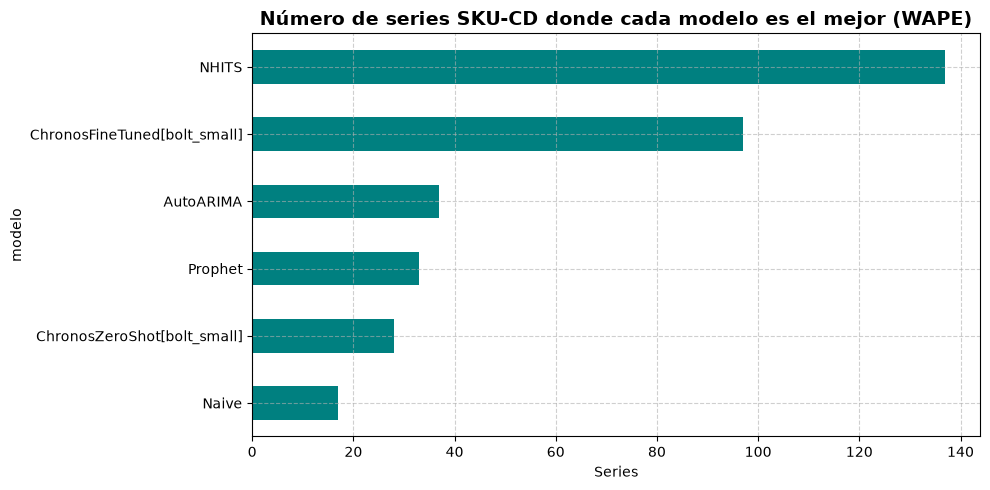

In [140]:
# Cuántas series gana cada modelo (por WAPE)
conteo = mejor_serie["modelo"].value_counts()
print(conteo)

# Listas de series por modelo: grupos["NHITS"], grupos["ChronosZeroShot[bolt_small]"], ...
grupos = {modelo: g.index.tolist() for modelo, g in mejor_serie.groupby("modelo")}

plt.figure(figsize=(10, 5))
conteo.sort_values().plot(kind="barh", color="teal")
plt.title("Número de series SKU-CD donde cada modelo es el mejor (WAPE)", fontsize=14, fontweight="bold")
plt.xlabel("Series")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

In [141]:
from statsmodels.tsa.seasonal import seasonal_decompose

def fuerza_estacional(s, periodo=13):
    if len(s) < 2 * periodo or s.std() == 0:
        return np.nan
    d = seasonal_decompose(s, model="additive", period=periodo)
    est, res = d.seasonal, d.resid.dropna()
    return max(0, 1 - res.var() / (est.loc[res.index] + res).var())

perfil = train_nx.groupby("unique_id")["y"].agg(
    semanas="size",
    media="mean",
    pct_ceros=lambda s: (s == 0).mean() * 100,
    cv=lambda s: s.std() / s.mean() if s.mean() > 0 else np.nan,   # variabilidad relativa
)
perfil["fuerza_estacional"] = (train_nx.set_index("ds")
                               .groupby("unique_id")["y"]
                               .apply(fuerza_estacional))

# Ganador por WAPE y margen de victoria: cuánto peor es el segundo que el mejor
ganadores = pd.DataFrame({
    "mejor_modelo": mejor_serie["modelo"],
    "margen_%": (segundo_serie["WAPE"] / mejor_serie["WAPE"].replace(0, np.nan) - 1) * 100,
})

resumen_grupos = (ganadores.join(perfil)
                  .groupby("mejor_modelo")[["semanas", "media", "pct_ceros", "cv", "fuerza_estacional", "margen_%"]]
                  .median()
                  .assign(n_series=conteo)
                  .sort_values("n_series", ascending=False))
resumen_grupos.round(2)

,semanas,media,pct_ceros,cv,fuerza_estacional,margen_%,n_series
mejor_modelo,,,,,,,
NHITS,127.0,729.91,0.00,0.52,0.48,17.00,137
ChronosFineTuned[bolt_small],127.0,693.20,0.00,0.48,0.45,14.30,97
AutoARIMA,127.0,785.83,0.00,0.48,0.53,9.18,37
Prophet,127.0,717.52,0.00,0.42,0.53,10.84,33
ChronosZeroShot[bolt_small],127.0,1012.19,0.00,0.55,0.48,8.68,28
Naive,127.0,710.98,1.57,0.48,0.37,0.00,17


## Predicción del Siguiente Trimestre

Usamos Chronos ZeroShot como modelo de respaldo para las series que no alcanzan a tener suficientes datos (no cumplen el umbral de 104 semanas) para entrenarse con un modelo específico. Lo usamos por lo que no necesita ser entrenado sino que ya viene preentrenado de fábria.

In [142]:
modelo_respaldo = "ChronosZeroShot[bolt_small]"   # para series sin evaluación (cortas o nuevas)

asignacion = (pd.DataFrame({"item_id": historia.item_ids})
              .merge(mejor_serie["modelo"].rename_axis("item_id").reset_index(), on="item_id", how="left"))
asignacion["origen"] = np.where(asignacion["modelo"].isna(), "respaldo (sin evaluación)", "ganador por WAPE")
asignacion["modelo"] = asignacion["modelo"].fillna(modelo_respaldo)
asignacion = asignacion.set_index("item_id")

items_por_modelo = {m: g.index.tolist() for m, g in asignacion.groupby("modelo")}

print(asignacion["modelo"].value_counts())
print(asignacion["origen"].value_counts())

modelo
NHITS                           137
ChronosFineTuned[bolt_small]     97
ChronosZeroShot[bolt_small]      42
AutoARIMA                        37
Prophet                          33
Naive                            17
Name: count, dtype: int64
origen
ganador por WAPE             349
respaldo (sin evaluación)     14
Name: count, dtype: int64


Ahora vamos a entrenar cada una de las series con su mejor modelo

In [143]:
config_ag = {
    "Naive": ("Naive", {}),
    "SeasonalNaive": ("SeasonalNaive", {"season_length": 13}),
    "AutoARIMA": ("AutoARIMA", {"season_length": 13, "max_d": 1, "max_D": 1}),
    "ChronosZeroShot[bolt_small]": ("Chronos", {"model_path": "bolt_small", "ag_args": {"name_suffix": "ZeroShot"}}),
    "ChronosFineTuned[bolt_small]": ("Chronos", {"model_path": "bolt_small", "fine_tune": True,
                                                 "ag_args": {"name_suffix": "FineTuned"}}),
}

modelos_ag = [m for m in items_por_modelo if m in config_ag]
hp = {}
for m in modelos_ag:
    familia, cfg = config_ag[m]
    hp.setdefault(familia, []).append(cfg)

predictor_final = TimeSeriesPredictor(
    prediction_length=horizonte,
    target="target",
    eval_metric="MASE",
    eval_metric_seasonal_period=13,
    path="modelos/final_por_serie",
)
predictor_final.fit(historia, hyperparameters=hp, enable_ensemble=False)

partes = []
for m in modelos_ag:
    p = predictor_final.predict(historia.loc[items_por_modelo[m]], model=m)[["mean", "0.1", "0.9"]].reset_index()
    p["modelo"] = m
    partes.append(p)

Beginning AutoGluon training...
AutoGluon will save models to '/Users/teo/Documents/Parcial-Forecasting/modelos/final_por_serie'
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.12.14
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 25.6.0: Fri Jul 31 19:16:20 PDT 2026; root:xnu-12377.161.14~5/RELEASE_ARM64_T8142
CPU Count:          10
Pytorch Version:    2.10.0
CUDA Version:       CUDA is not available
GPU Count:          WARNING: Exception was raised when calculating GPU count (AssertionError)
Memory Avail:       5.60 GB / 24.00 GB (23.3%)
Disk Space Avail:   74.47 GB / 460.38 GB (16.2%)

Fitting with arguments:
{'enable_ensemble': False,
 'eval_metric': MASE,
 'eval_metric_seasonal_period': 13,
 'hyperparameters': {'AutoARIMA': [{'max_D': 1,
                                    'max_d': 1,
                                    'season_length': 13}],
                     'Chronos': [{'ag_arg

In [144]:
historia_nx = (historia.reset_index()
               .rename(columns={"item_id": "unique_id", "timestamp": "ds", "target": "y"}))

if "NHITS" in items_por_modelo:
    from neuralforecast.losses.pytorch import MQLoss
    nf_final = NeuralForecast(
        models=[NHITS(h=horizonte, input_size=52, loss=MQLoss(level=[80]),   # mediana + intervalo 80 %
                      scaler_type="robust", max_steps=500, start_padding_enabled=True, random_seed=42)],
        freq="W-SUN",
    )
    nf_final.fit(df=historia_nx)                 # modelo global: entrena con todas las series
    p = nf_final.predict()
    if "unique_id" not in p.columns:
        p = p.reset_index()
    p = (p[p["unique_id"].isin(items_por_modelo["NHITS"])]
         .rename(columns={"unique_id": "item_id", "ds": "timestamp",
                          "NHITS-median": "mean", "NHITS-lo-80": "0.1", "NHITS-hi-80": "0.9"})
         [["item_id", "timestamp", "mean", "0.1", "0.9"]])
    p["modelo"] = "NHITS"
    partes.append(p)

if "Prophet" in items_por_modelo:
    filas = []
    for uid in items_por_modelo["Prophet"]:
        g = historia_nx[historia_nx["unique_id"] == uid]
        m = Prophet(yearly_seasonality=False, weekly_seasonality=False, daily_seasonality=False,
                    interval_width=0.8)
        m.add_seasonality(name="trimestral", period=365.25 / 4, fourier_order=5)
        m.fit(g[["ds", "y"]])
        futuro = m.make_future_dataframe(periods=horizonte, freq="W-SUN", include_history=False)
        f = m.predict(futuro)[["ds", "yhat", "yhat_lower", "yhat_upper"]]
        f.columns = ["timestamp", "mean", "0.1", "0.9"]
        f["item_id"] = uid
        filas.append(f)
    p = pd.concat(filas, ignore_index=True)
    p["modelo"] = "Prophet"
    partes.append(p)

Seed set to 42
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


┏━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name                ┃ Type          ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ loss                │ MQLoss        │      3 │ train │     0 │
│ 1 │ hist_cat_embeddings │ ModuleList    │      0 │ train │     0 │
│ 2 │ futr_cat_embeddings │ ModuleList    │      0 │ train │     0 │
│ 3 │ stat_cat_embeddings │ ModuleList    │      0 │ train │     0 │
│ 4 │ padder_train        │ ConstantPad1d │      0 │ train │     0 │
│ 5 │ scaler              │ TemporalNorm  │      0 │ train │     0 │
│ 6 │ blocks              │ ModuleList    │  2.5 M │ train │     0 │
└───┴─────────────────────┴───────────────┴────────┴───────┴───────┘

Trainable params: 2.5 M                                                                                            
Non-trainable params: 3                                                                                            
Total params: 2.5 M                                                                                                
Total estimated model params size (MB): 10.173                                                                     
Modules in train mode: 37                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

/Users/teo/.venv/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install "ipywidgets" for Jupyter 
support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Users/teo/.venv/lib/python3.12/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, 
LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

`Trainer.fit` stopped: `max_steps=500` reached.


GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


/Users/teo/.venv/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install "ipywidgets" for Jupyter 
support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Users/teo/.venv/lib/python3.12/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


In [145]:
pronostico = pd.concat([pd.DataFrame(p) for p in partes], ignore_index=True)
cols = ["mean", "0.1", "0.9"]
pronostico[cols] = pronostico[cols].clip(lower=0)            # no puede haber unidades negativas
pronostico = pronostico.set_index(["item_id", "timestamp"]).sort_index()

assert pronostico.index.get_level_values("item_id").nunique() == historia.num_items, "Faltan series"
pronostico.groupby("modelo").size() / horizonte                 # series pronosticadas por cada modelo

modelo
AutoARIMA                        37.0
ChronosFineTuned[bolt_small]     97.0
ChronosZeroShot[bolt_small]      42.0
NHITS                           137.0
Naive                            17.0
Prophet                          33.0
dtype: float64

### Predicción Semanal de cada SKU-DC

Mostramos la predicción de la demanda de cada serie para cada semana del siguiente trimestre, con su intervalo de confianza

In [146]:
tabla_pronostico = pronostico[["mean", "0.1", "0.9", "modelo"]].reset_index()
tabla_pronostico[["SKU_NBR", "DC_ID"]] = tabla_pronostico["item_id"].str.split("_", expand=True)
tabla_pronostico = (tabla_pronostico
                    .rename(columns={"timestamp": "semana", "mean": "pronostico",
                                     "0.1": "limite_inferior", "0.9": "limite_superior"})
                    [["SKU_NBR", "DC_ID", "modelo", "semana", "pronostico", "limite_inferior", "limite_superior"]]
                    .round(0))
tabla_pronostico

,SKU_NBR,DC_ID,modelo,semana,pronostico,limite_inferior,limite_superior
0,100032,KC,ChronosZeroShot[bolt_small],2026-09-06,1038.0,686.0,1520.0
1,100032,KC,ChronosZeroShot[bolt_small],2026-09-13,895.0,473.0,1389.0
2,100032,KC,ChronosZeroShot[bolt_small],2026-09-20,947.0,466.0,1463.0
3,100032,KC,ChronosZeroShot[bolt_small],2026-09-27,1365.0,818.0,1982.0
4,100032,KC,ChronosZeroShot[bolt_small],2026-10-04,1687.0,1020.0,2425.0
...,...,...,...,...,...,...,...
6166,998700,OR,AutoARIMA,2026-11-29,643.0,358.0,927.0
6167,998700,OR,AutoARIMA,2026-12-06,647.0,359.0,934.0
6168,998700,OR,AutoARIMA,2026-12-13,642.0,351.0,933.0
6169,998700,OR,AutoARIMA,2026-12-20,638.0,346.0,931.0


In [147]:
siguiente = "2026Q4"

pron_q = pronostico.reset_index()
pron_q["trimestre"] = pron_q["timestamp"].dt.to_period("Q").astype(str)

demanda_siguiente = (pron_q[pron_q["trimestre"] == siguiente]
                     .groupby("item_id")
                     .agg(modelo=("modelo", "first"),
                          pronostico=("mean", "sum"),
                          limite_inferior=("0.1", "sum"),
                          limite_superior=("0.9", "sum"))
                     .join(asignacion["origen"]))
demanda_siguiente[["SKU_NBR", "DC_ID"]] = demanda_siguiente.index.to_series().str.split("_", expand=True)
demanda_siguiente = demanda_siguiente.sort_values("pronostico", ascending=False).round(0)
demanda_siguiente

,modelo,pronostico,limite_inferior,limite_superior,origen,SKU_NBR,DC_ID
item_id,,,,,,,
910693_OR,NHITS,263075.0,191212.0,374385.0,ganador por WAPE,910693,OR
571810_OR,ChronosZeroShot[bolt_small],117568.0,69156.0,198881.0,ganador por WAPE,571810,OR
740537_OR,ChronosZeroShot[bolt_small],113527.0,65027.0,188052.0,ganador por WAPE,740537,OR
910693_MA,Prophet,107910.0,75172.0,139850.0,ganador por WAPE,910693,MA
692270_OR,ChronosZeroShot[bolt_small],102119.0,51937.0,172618.0,ganador por WAPE,692270,OR
...,...,...,...,...,...,...,...
214174_OR,AutoARIMA,1163.0,0.0,11289.0,ganador por WAPE,214174,OR
822572_OR,ChronosZeroShot[bolt_small],932.0,64.0,2828.0,ganador por WAPE,822572,OR
478059_KC,ChronosFineTuned[bolt_small],777.0,45.0,2049.0,ganador por WAPE,478059,KC


In [148]:
ax.set_title(f"SKU {item.split('_')[0]} - CD {item.split('_')[1]} ({asignacion.loc[item, 'modelo']})",
                fontsize=12, fontweight="bold")

Text(0.5, 1.0, 'SKU 171322 - CD KC (Naive)')

### Visualización de Algunas Series

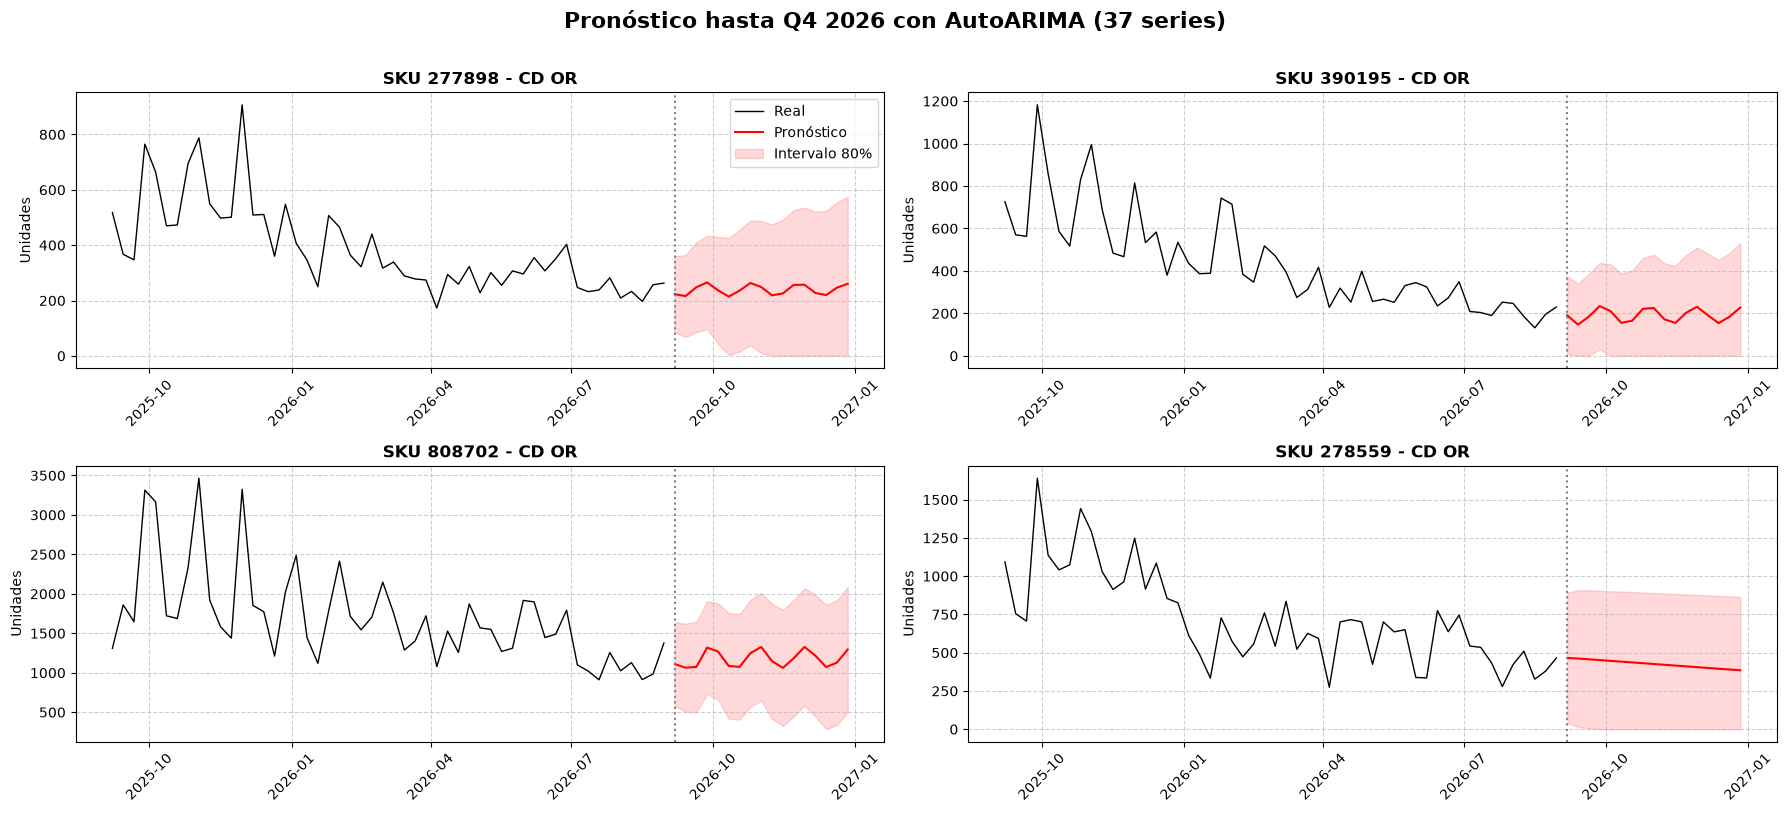

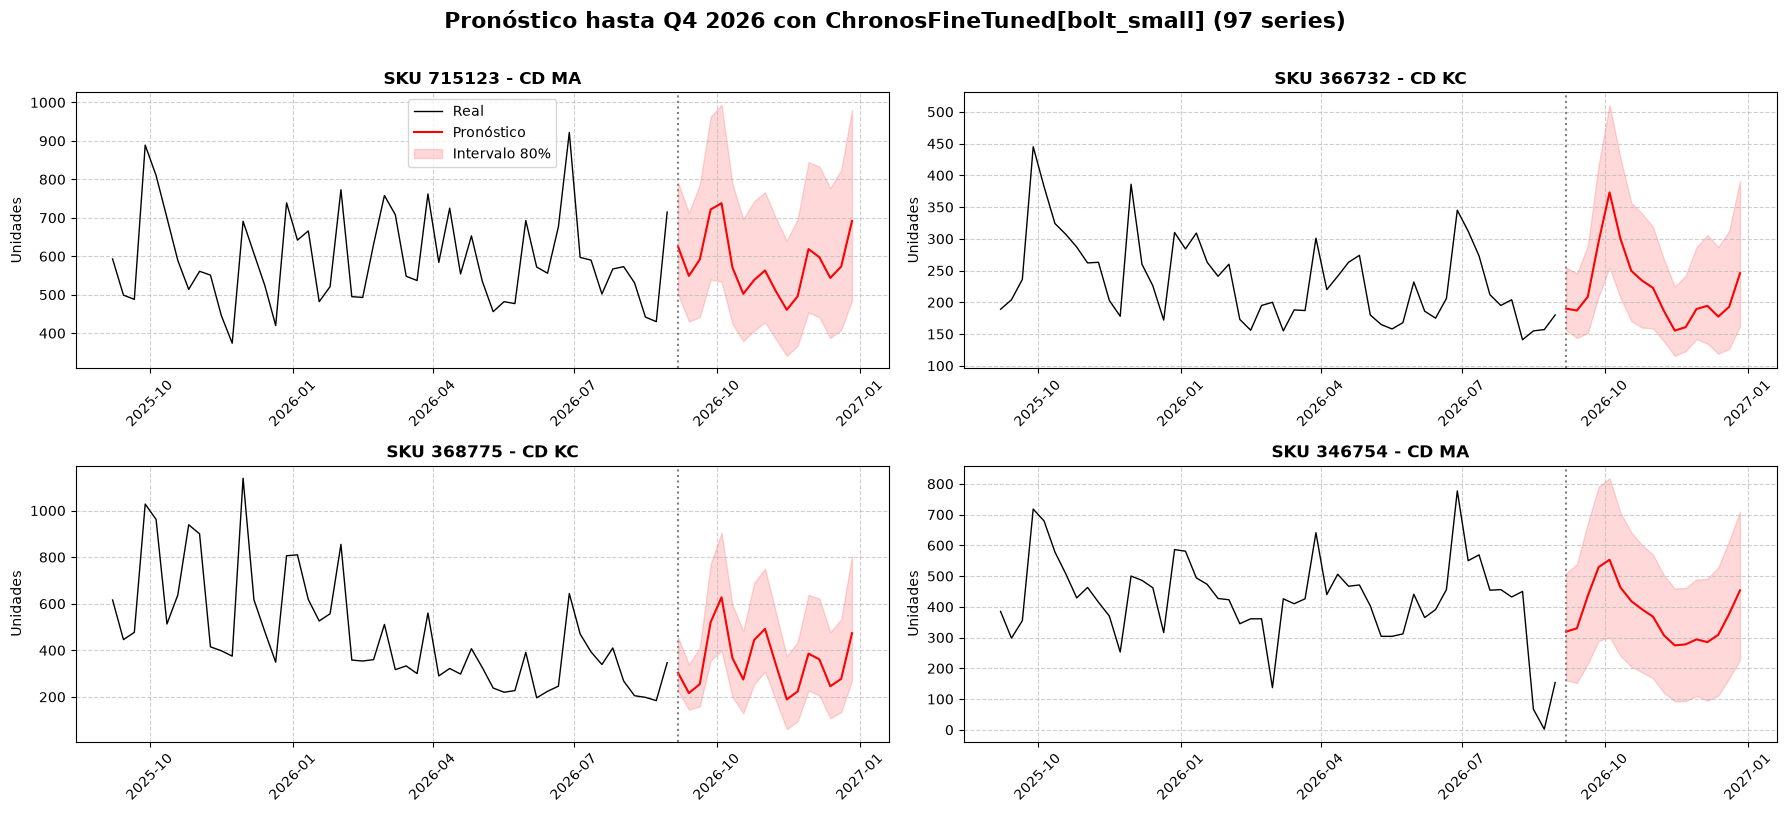

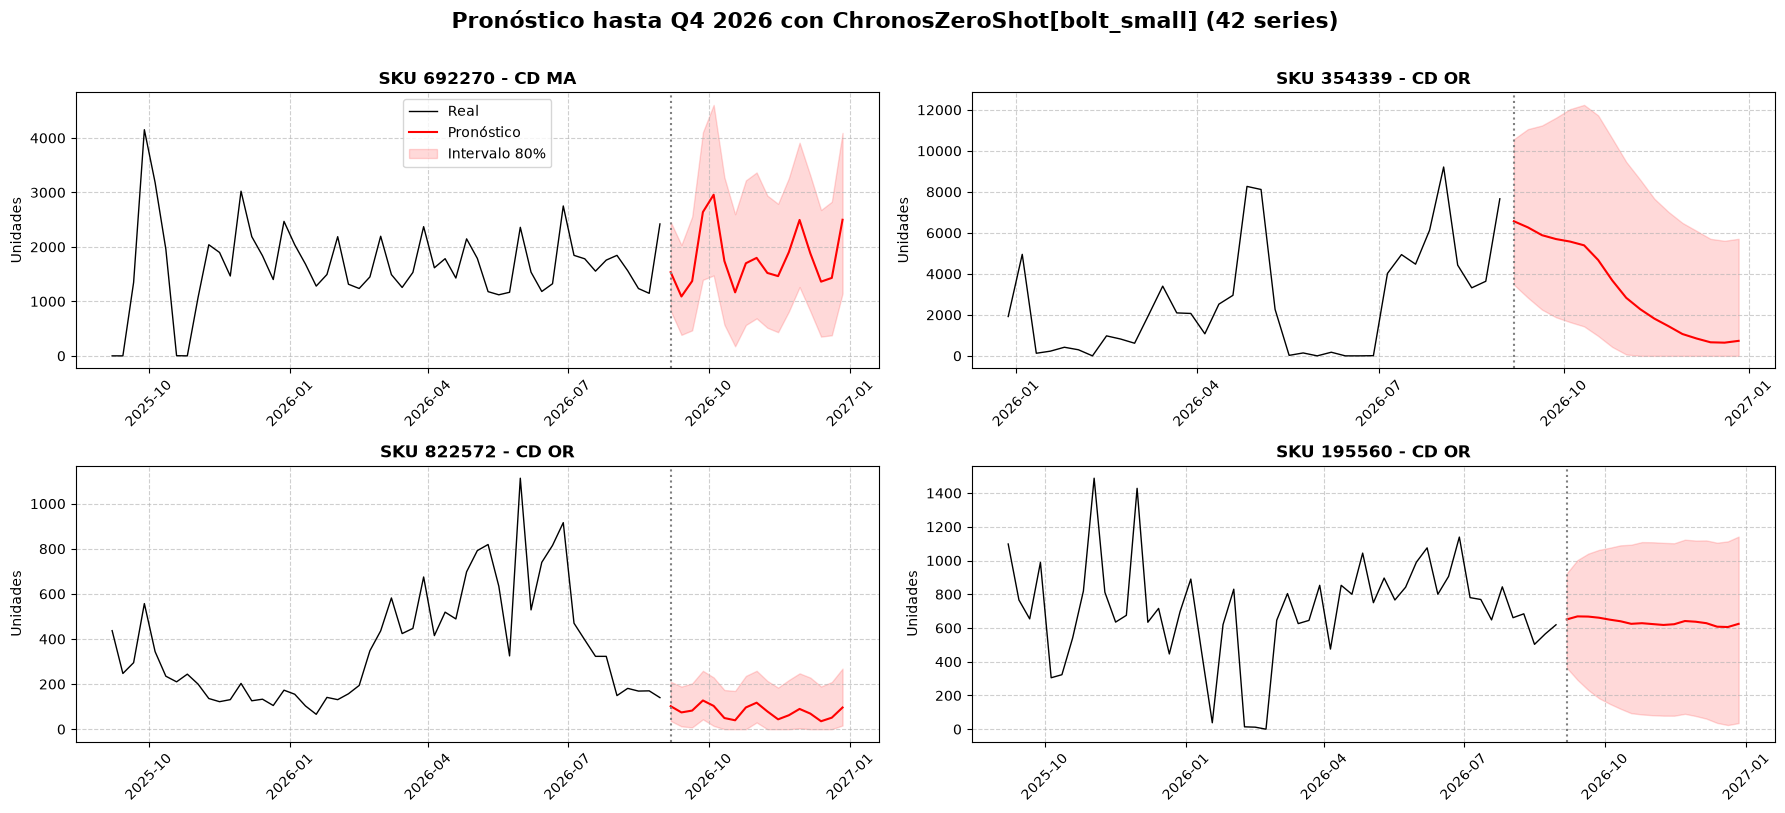

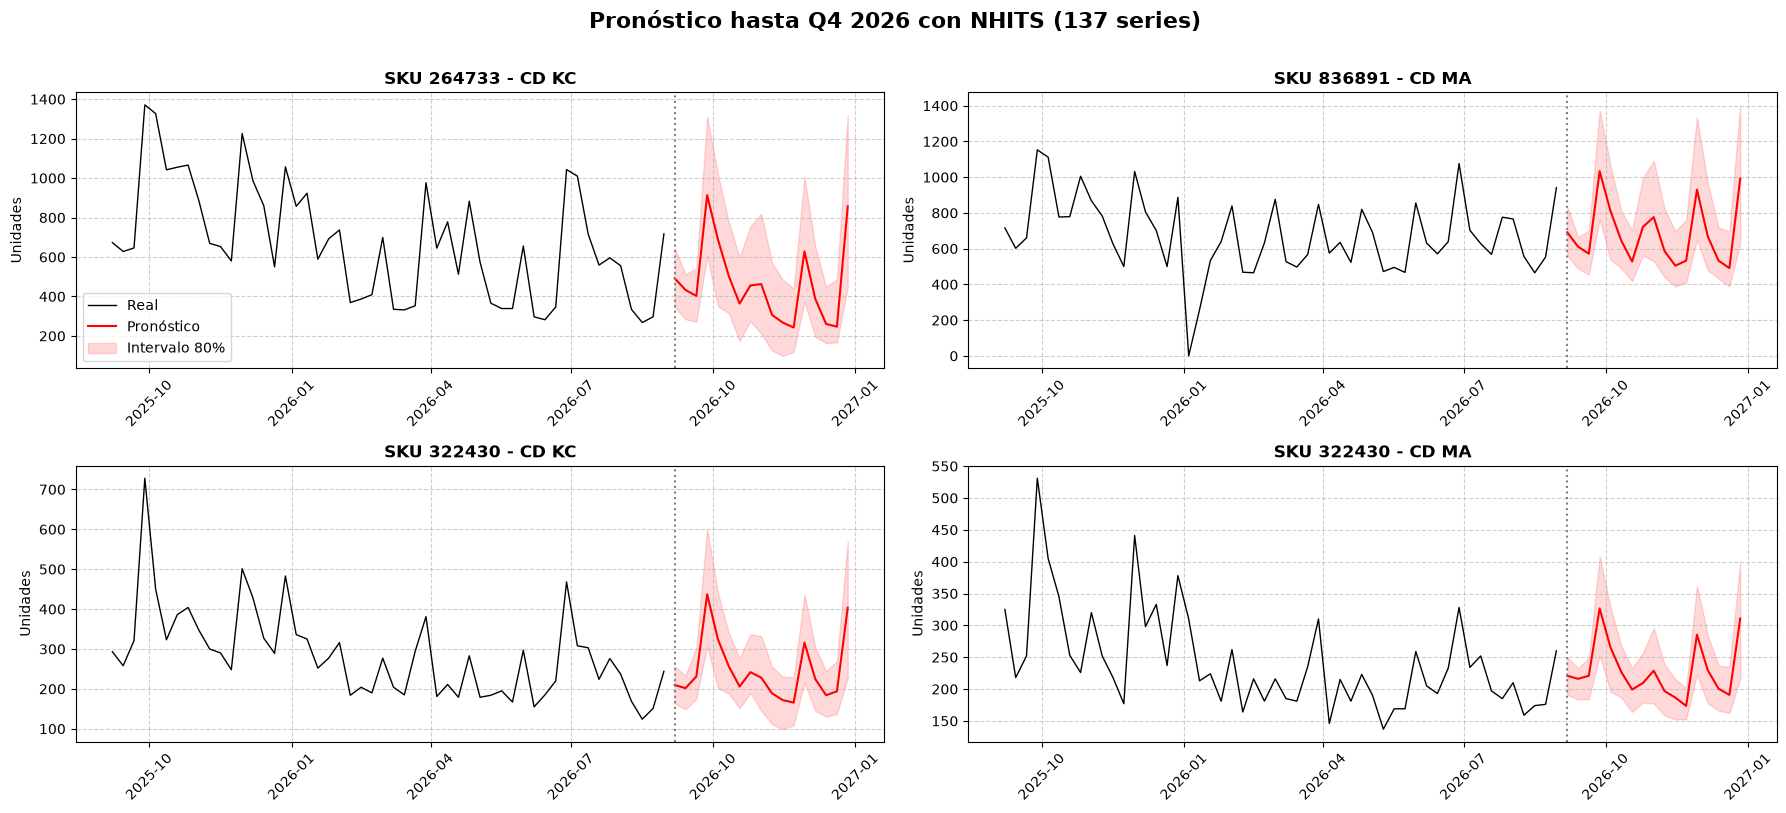

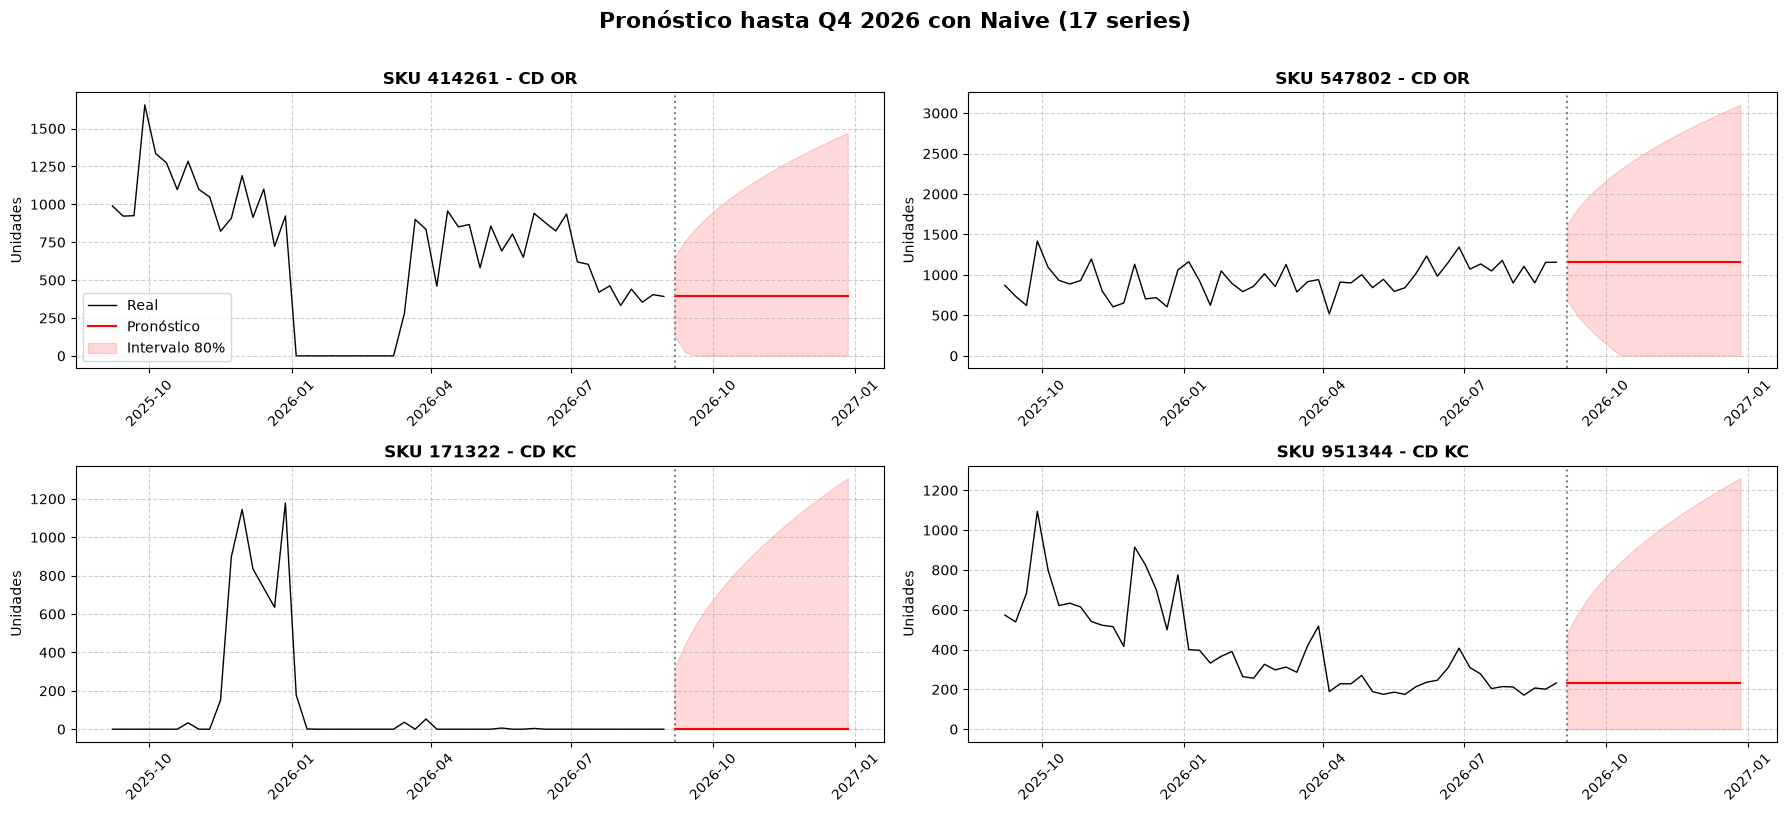

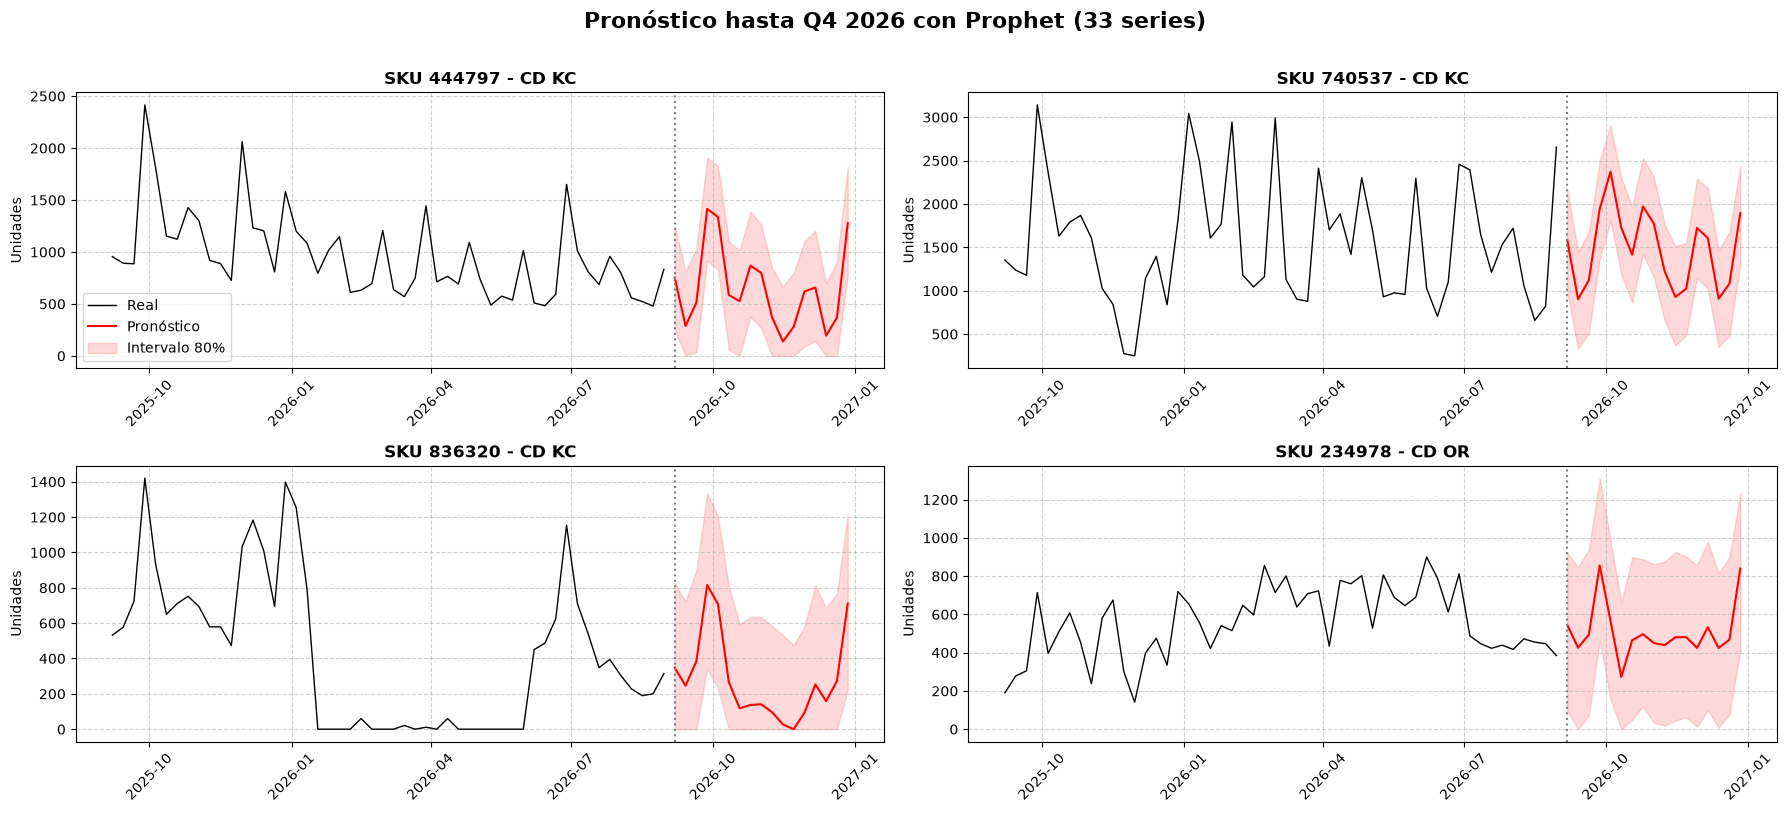

In [149]:
for modelo, items in items_por_modelo.items():
    muestra = pd.Series(items).sample(min(4, len(items))).tolist()
    n_filas = math.ceil(len(muestra) / 2)
    fig, axes = plt.subplots(n_filas, 2, figsize=(18, 4 * n_filas))
    axes = np.atleast_1d(axes).flatten()

    for ax, item in zip(axes, muestra):
        real_item = historia.loc[item]["target"].iloc[-52:]   # último año de historia
        pron_item = pronostico.loc[item]
        ax.plot(real_item, color="black", linewidth=1, label="Real")
        ax.plot(pron_item["mean"], color="red", linewidth=1.5, label="Pronóstico")
        ax.fill_between(pron_item.index, pron_item["0.1"], pron_item["0.9"], color="red", alpha=0.15, label="Intervalo 80%")
        ax.axvline(pron_item.index[0], color="gray", linestyle=":")
        ax.set_title(f"SKU {item.split('_')[0]} - CD {item.split('_')[1]}", fontsize=12, fontweight="bold")
        ax.set_ylabel("Unidades")

    for ax in axes[len(muestra):]:
        ax.set_visible(False)

    # Ajustes estéticos
    for ax in axes[:len(muestra)]:
        ax.grid(True, linestyle="--", alpha=0.6)
        ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))   # un tick por trimestre
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
        ax.tick_params(axis="x", rotation=45)
    axes[0].legend()

    plt.suptitle(f"Pronóstico hasta Q4 2026 con {modelo} ({len(items)} series)",
                 fontsize=16, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()